# Gold EDA for T-14 Hotel Cancellation Modeling

Review the delivered H1 and H2 Gold tables, design model inputs, and specify chronological splits for T-14 cancellation modeling. H1 and H2 will have separate models. Gold contains final booking records; feature timing requires review.

- **I. Data Audit:** handoff, population, labels and data-quality checks.
- **II. Feature Design:** feature review, model choice and preprocessing decisions.
- **III. Data Split:** chronological split comparisons, the selected calendar and final split audit.


## I. Data Audit


### I.1 Objective and Data Sources


#### I.1.1 Imports

Import the libraries used throughout this notebook.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyspark
from IPython.display import display

#### I.1.2 Set Up PySpark Session

Start a local Spark session for reading the delivered Gold Parquet tables.

In [2]:
# Initialize SparkSession
spark = (pyspark.sql.SparkSession.builder
         .appName('hotel_gold_eda')
         .master('local[2]')
         .getOrCreate())

# Keep notebook output focused on the audit results.
spark.sparkContext.setLogLevel('ERROR')
print('Spark version:', spark.version)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/21 06:17:46 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.5


#### I.1.3 Set Up Data Sources

Locate the sibling data pipeline and load its feature contract. This config only identifies the Gold handoff; no split settings are chosen here.

In [3]:
def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        gold = candidate / 'Data pipeline' / 'hotel_booking_pipeline' / 'datamart' / 'gold'
        if gold.exists():
            return candidate
    raise FileNotFoundError('Run this notebook with the Project folder accessible.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
GOLD_ROOT = PROJECT_ROOT / 'Data pipeline' / 'hotel_booking_pipeline' / 'datamart' / 'gold'
CONTRACT_PATH = GOLD_ROOT / 'feature_contract.json'
HOTELS = ('H1', 'H2')

contract = json.loads(CONTRACT_PATH.read_text(encoding='utf-8'))
print('Project root:', PROJECT_ROOT)
print('Gold root:', GOLD_ROOT)

Project root: /workspace/Project
Gold root: /workspace/Project/Data pipeline/hotel_booking_pipeline/datamart/gold


#### I.1.4 Load the Delivered Gold Tables

The joined model dataset is the modeling input. The feature and label stores are read only to reconcile the handoff and audit final outcomes. No table is rebuilt here.

In [4]:
table_names = {
    'model': ('model_dataset', 'gold_model_dataset'),
    'features': ('features', 'gold_feature_store'),
    'labels': ('labels', 'gold_label_store'),
}

spark_tables = {}
tables = {}
source_rows = []
for hotel in HOTELS:
    spark_tables[hotel] = {}
    tables[hotel] = {}
    for role, (folder, stem) in table_names.items():
        path = GOLD_ROOT / folder / f'{stem}_{hotel}.parquet'
        if not path.is_dir():
            raise FileNotFoundError(path)
        sdf = spark.read.parquet(str(path))
        spark_tables[hotel][role] = sdf
        tables[hotel][role] = sdf.toPandas()
        source_rows.append({'Hotel': hotel, 'Table': role, 'Rows': len(tables[hotel][role]),
                            'Columns': len(sdf.columns), 'Path': str(path)})

display(pd.DataFrame(source_rows))


,Hotel,Table,Rows,Columns,Path
0,H1,model,20140,41,/workspace/Project/Data pipeline/hotel_booking...
1,H1,features,20140,40,/workspace/Project/Data pipeline/hotel_booking...
2,H1,labels,20140,5,/workspace/Project/Data pipeline/hotel_booking...
3,H2,model,38233,41,/workspace/Project/Data pipeline/hotel_booking...
4,H2,features,38233,40,/workspace/Project/Data pipeline/hotel_booking...
5,H2,labels,38233,5,/workspace/Project/Data pipeline/hotel_booking...


**Observation:** All six Gold directories loaded. H1 has 20,140 rows in each store and H2 has 38,233; the joined, feature, and label tables have 41, 40, and 5 columns respectively.

### I.2 Gold Handoff Audit


#### I.2.1 Check Schema and Row Counts

Compare each joined table with the explicit contract. Candidate predictors are columns available for review, not automatically approved model inputs. README row and positive counts are references, not values to force the tables to match.


In [5]:
expected_columns = (contract['metadata_only'] + contract['numeric_predictors']
                    + contract['categorical_predictors'] + [contract['target']])
expected_types = {column: 'int' for column in contract['numeric_predictors']}
for column in ('ADR', 'EURUSD', 'HotelSearchInterest', 'FlightSearchInterest'):
    expected_types[column] = 'double'
expected_types.update({column: 'string' for column in contract['categorical_predictors']})
expected_types.update({'Booking_ID': 'string', 'Hotel': 'string',
                       'EstimatedRoomCount': 'int', 'IsCanceled': 'int'})
for column in ('ArrivalDate', 'BookingCreatedDate', 'CutoffDate', 'FXObservationDate',
               'TrendWeekStart', 'TrendWeekEnd', 'TrendAvailableDate'):
    expected_types[column] = 'date'

schema_rows = []
for hotel in HOTELS:
    sdf = spark_tables[hotel]['model']
    df = tables[hotel]['model']
    actual_types = {field.name: field.dataType.simpleString() for field in sdf.schema.fields}
    missing = sorted(set(expected_columns) - set(sdf.columns))
    extra = sorted(set(sdf.columns) - set(expected_columns))
    type_mismatches = [f'{column}: {actual_types[column]} != {expected}'
                       for column, expected in expected_types.items()
                       if column in actual_types and actual_types[column] != expected]
    schema_rows.append({'Hotel': hotel, 'Rows': len(df), 'Columns': len(df.columns),
                        'Positive labels': int(df['IsCanceled'].sum()) if 'IsCanceled' in df else None,
                        'Missing columns': missing, 'Extra columns': extra,
                        'Type mismatches': type_mismatches})
schema_report = pd.DataFrame(schema_rows)
display(schema_report)
print('Contract columns:', len(expected_columns), '| numeric candidates:',
      len(contract['numeric_predictors']), '| categorical candidates:',
      len(contract['categorical_predictors']))


,Hotel,Rows,Columns,Positive labels,Missing columns,Extra columns,Type mismatches
0,H1,20140,41,1518,[],[],[]
1,H2,38233,41,4536,[],[],[]


Contract columns: 41 | numeric candidates: 23 | categorical candidates: 7


**Observation:** Both model tables match the 41-column contract: no missing, extra, or type-mismatched columns. H1 has 20,140 rows and 1,518 positive labels (7.54%); H2 has 38,233 rows and 4,536 positive labels (11.86%).

#### I.2.2 Check Booking Keys

Booking_ID must be present and unique within each table. Hotel must match the H1/H2 file. Matching-looking bookings are allowed; duplicated IDs are not.


In [6]:
key_rows = []
for hotel in HOTELS:
    for role, df in tables[hotel].items():
        ids = df['Booking_ID']
        missing_id = ids.isna() | ids.astype('string').str.strip().eq('').fillna(False)
        duplicated_id = ids.duplicated(keep=False) & ~missing_id
        wrong_hotel = df['Hotel'].isna() | df['Hotel'].ne(hotel)
        key_rows.append({'Hotel': hotel, 'Table': role, 'Rows': len(df),
                         'Missing ID rows': int(missing_id.sum()),
                         'Duplicate ID rows': int(duplicated_id.sum()),
                         'Wrong hotel rows': int(wrong_hotel.sum()),
                         'Example duplicate IDs': ids[duplicated_id].drop_duplicates().head(5).tolist()})
key_report = pd.DataFrame(key_rows)
display(key_report)

h1_ids = set(tables['H1']['model']['Booking_ID'].dropna())
h2_ids = set(tables['H2']['model']['Booking_ID'].dropna())
print('Booking IDs appearing in both hotels:', len(h1_ids & h2_ids))


,Hotel,Table,Rows,Missing ID rows,Duplicate ID rows,Wrong hotel rows,Example duplicate IDs
0,H1,model,20140,0,0,0,[]
1,H1,features,20140,0,0,0,[]
2,H1,labels,20140,0,0,0,[]
3,H2,model,38233,0,0,0,[]
4,H2,features,38233,0,0,0,[]
5,H2,labels,38233,0,0,0,[]


Booking IDs appearing in both hotels: 0


**Observation:** Every Gold table has zero missing Booking_IDs, duplicate Booking_ID rows, or wrong Hotel values. No Booking_ID appears in both the H1 and H2 model tables.

#### I.2.3 Reconcile the Joined Dataset with the Stores

Compare Booking_ID sets across the three Gold tables. When keys are unique, compare all supplied feature values and the target. A mismatch is reported rather than silently repaired.


In [7]:
reconciliation_rows = []
reconciliation_examples = {}
feature_columns = contract['metadata_only'] + contract['numeric_predictors'] + contract['categorical_predictors']
for hotel in HOTELS:
    model = tables[hotel]['model']
    features = tables[hotel]['features']
    labels = tables[hotel]['labels']
    model_ids, feature_ids, label_ids = (set(df['Booking_ID'].dropna())
                                         for df in (model, features, labels))
    unique_keys = all(df['Booking_ID'].notna().all() and df['Booking_ID'].is_unique
                      for df in (model, features, labels))
    feature_mismatch_rows = None
    label_mismatch_rows = None
    examples = {}
    if unique_keys and model_ids == feature_ids == label_ids:
        model_features = model.set_index('Booking_ID')[feature_columns[1:]].sort_index()
        store_features = features.set_index('Booking_ID')[feature_columns[1:]].sort_index()
        different = ~(model_features.eq(store_features)
                      | (model_features.isna() & store_features.isna()))
        feature_mismatch_rows = int(different.any(axis=1).sum())
        model_labels = model.set_index('Booking_ID')['IsCanceled'].sort_index()
        store_labels = labels.set_index('Booking_ID')['IsCanceled'].sort_index()
        label_different = ~(model_labels.eq(store_labels)
                            | (model_labels.isna() & store_labels.isna()))
        label_mismatch_rows = int(label_different.sum())
        examples['feature_value_mismatch'] = different.index[different.any(axis=1)][:5].tolist()
        examples['label_mismatch'] = label_different.index[label_different][:5].tolist()
    reconciliation_rows.append({
        'Hotel': hotel, 'Unique keys in all tables': unique_keys,
        'Model IDs absent from features': len(model_ids - feature_ids),
        'Feature IDs absent from model': len(feature_ids - model_ids),
        'Model IDs absent from labels': len(model_ids - label_ids),
        'Label IDs absent from model': len(label_ids - model_ids),
        'Feature value mismatch rows': feature_mismatch_rows,
        'Label mismatch rows': label_mismatch_rows,
    })
    examples['model_only_feature'] = sorted(model_ids - feature_ids)[:5]
    examples['model_only_label'] = sorted(model_ids - label_ids)[:5]
    reconciliation_examples[hotel] = examples
reconciliation_report = pd.DataFrame(reconciliation_rows)
display(reconciliation_report)
print('Example mismatches:', reconciliation_examples)


,Hotel,Unique keys in all tables,Model IDs absent from features,Feature IDs absent from model,Model IDs absent from labels,Label IDs absent from model,Feature value mismatch rows,Label mismatch rows
0,H1,True,0,0,0,0,0,0
1,H2,True,0,0,0,0,0,0


Example mismatches: {'H1': {'feature_value_mismatch': [], 'label_mismatch': [], 'model_only_feature': [], 'model_only_label': []}, 'H2': {'feature_value_mismatch': [], 'label_mismatch': [], 'model_only_feature': [], 'model_only_label': []}}


**Observation:** For both hotels, the model, feature, and label stores have identical Booking_ID sets. All compared feature values and labels match the joined model dataset; the reported mismatch counts are zero.

### I.3 T-14 Population and Label Audit


#### I.3.1 Check the Prediction Cutoff

CutoffDate is fourteen days before scheduled arrival. LeadTime of at least fourteen means the booking existed by that day. BookingCreatedDate is derived from LeadTime in Silver, so its consistency check does not independently verify the true creation timestamp.


In [8]:
cutoff_rows = []
cutoff_examples = {}
for hotel in HOTELS:
    df = tables[hotel]['model'].copy()
    arrival = pd.to_datetime(df['ArrivalDate'], errors='coerce')
    cutoff = pd.to_datetime(df['CutoffDate'], errors='coerce')
    created = pd.to_datetime(df['BookingCreatedDate'], errors='coerce')
    lead = pd.to_numeric(df['LeadTime'], errors='coerce')
    failed = {
        'Missing or invalid dates': arrival.isna() | cutoff.isna() | created.isna(),
        'Wrong T-14 cutoff': cutoff.ne(arrival - pd.Timedelta(days=14)),
        'LeadTime below 14': lead.isna() | lead.lt(14),
        'Created-date inconsistency': created.ne(arrival - pd.to_timedelta(lead, unit='D')),
    }
    cutoff_rows.append({'Hotel': hotel, **{name: int(mask.sum()) for name, mask in failed.items()}})
    cutoff_examples[hotel] = {name: df.loc[mask, 'Booking_ID'].head(5).tolist()
                              for name, mask in failed.items() if mask.any()}
cutoff_report = pd.DataFrame(cutoff_rows)
display(cutoff_report)
print('Example Booking_IDs:', cutoff_examples)


,Hotel,Missing or invalid dates,Wrong T-14 cutoff,LeadTime below 14,Created-date inconsistency
0,H1,0,0,0,0
1,H2,0,0,0,0


Example Booking_IDs: {'H1': {}, 'H2': {}}


**Observation:** Both hotels have zero missing or invalid dates, wrong T-14 cutoffs, LeadTime values below 14, or inconsistencies between BookingCreatedDate and ArrivalDate minus LeadTime.

#### I.3.2 Check Stay Scope

The delivered Gold population requires positive PartySize and TotalNights. Their arithmetic is checked against the original guest and night components retained in Gold.


In [9]:
scope_rows = []
scope_examples = {}
for hotel in HOTELS:
    df = tables[hotel]['model']
    party = pd.to_numeric(df['PartySize'], errors='coerce')
    nights = pd.to_numeric(df['TotalNights'], errors='coerce')
    guest_sum = df[['Adults', 'Children', 'Babies']].sum(axis=1, min_count=3)
    night_sum = df[['StaysInWeekNights', 'StaysInWeekendNights']].sum(axis=1, min_count=2)
    failed = {
        'Nonpositive or missing PartySize': party.isna() | party.le(0),
        'Nonpositive or missing TotalNights': nights.isna() | nights.le(0),
        'PartySize arithmetic mismatch': party.ne(guest_sum),
        'TotalNights arithmetic mismatch': nights.ne(night_sum),
    }
    scope_rows.append({'Hotel': hotel, **{name: int(mask.sum()) for name, mask in failed.items()}})
    scope_examples[hotel] = {name: df.loc[mask, 'Booking_ID'].head(5).tolist()
                             for name, mask in failed.items() if mask.any()}
scope_report = pd.DataFrame(scope_rows)
display(scope_report)
print('Example Booking_IDs:', scope_examples)


,Hotel,Nonpositive or missing PartySize,Nonpositive or missing TotalNights,PartySize arithmetic mismatch,TotalNights arithmetic mismatch
0,H1,0,0,0,0
1,H2,0,0,0,0


Example Booking_IDs: {'H1': {}, 'H2': {}}


**Observation:** Both hotels have zero nonpositive or missing PartySize and TotalNights values. PartySize equals Adults + Children + Babies, and TotalNights equals weekday plus weekend nights, for every audited row.

#### I.3.3 Check Labels Against Final Status

Final status and status date are audit fields, never predictors. A retained cancellation or no-show must be recorded after CutoffDate. Check-out timing differences are reported separately because the source contains documented date anomalies.


In [10]:
label_rows = []
label_examples = {}
for hotel in HOTELS:
    model = tables[hotel]['model']
    labels = tables[hotel]['labels']
    if not (model['Booking_ID'].is_unique and labels['Booking_ID'].is_unique):
        raise ValueError(f'{hotel}: resolve duplicate Booking_ID values before the label audit')
    joined = model[['Booking_ID', 'ArrivalDate', 'CutoffDate', 'TotalNights', 'IsCanceled']].merge(
        labels[['Booking_ID', 'ReservationStatus', 'ReservationStatusDate']],
        on='Booking_ID', how='left', validate='one_to_one')
    y = joined['IsCanceled']
    status = joined['ReservationStatus']
    status_date = pd.to_datetime(joined['ReservationStatusDate'], errors='coerce')
    cutoff = pd.to_datetime(joined['CutoffDate'], errors='coerce')
    arrival = pd.to_datetime(joined['ArrivalDate'], errors='coerce')
    valid_label = y.isin([0, 1])
    status_match = ((y.eq(0) & status.eq('Check-Out'))
                    | (y.eq(1) & status.isin(['Canceled', 'No-Show'])))
    late_outcome = ~(status.isin(['Canceled', 'No-Show']) &
                     (status_date.isna() | status_date.le(cutoff)))
    expected_checkout = arrival + pd.to_timedelta(joined['TotalNights'], unit='D')
    checkout_date_review = status.eq('Check-Out') & status_date.ne(expected_checkout)
    failed = {
        'Invalid or missing label': ~valid_label,
        'Label/status disagreement': ~status_match,
        'Missing status date': status_date.isna(),
        'Retained early cancellation/no-show': ~late_outcome,
        'Check-out date review (warning)': checkout_date_review,
    }
    label_rows.append({'Hotel': hotel, **{name: int(mask.sum()) for name, mask in failed.items()}})
    label_examples[hotel] = {name: joined.loc[mask, 'Booking_ID'].head(5).tolist()
                             for name, mask in failed.items() if mask.any()}
label_report = pd.DataFrame(label_rows)
display(label_report)
print('Example Booking_IDs:', label_examples)


,Hotel,Invalid or missing label,Label/status disagreement,Missing status date,Retained early cancellation/no-show,Check-out date review (warning)
0,H1,0,0,0,0,19
1,H2,0,0,0,0,5


Example Booking_IDs: {'H1': {'Check-out date review (warning)': ['H1-000025', 'H1-000314', 'H1-000804', 'H1-001658', 'H1-002346']}, 'H2': {'Check-out date review (warning)': ['H2-073462', 'H2-073943', 'H2-073944', 'H2-000235', 'H2-030601']}}


**Observation:** Both hotels have zero invalid labels, label/status disagreements, missing status dates, and retained cancellations or no-shows recorded on or before T-14. The separate Check-Out date review flags 19 H1 rows and 5 H2 rows; the printed Booking_IDs are examples for follow-up.

#### I.3.4 Inspect Check-Out Date Differences

For the Check-Out rows flagged in I.3.3, compare ReservationStatusDate with ArrivalDate + TotalNights. A negative difference means the recorded date is earlier; a positive difference means it is later. Show the signed difference and booking IDs before discussing a label-maturity rule. The recorded date is not verified as the physical checkout time or the exact time the label first became available.

In [11]:
checkout_date_summary = []
checkout_date_details = []

for hotel in HOTELS:
    model = tables[hotel]['model'][
        ['Booking_ID', 'Hotel', 'CutoffDate', 'ArrivalDate', 'TotalNights', 'IsCanceled']
    ]
    labels = tables[hotel]['labels'][
        ['Booking_ID', 'ReservationStatus', 'ReservationStatusDate']
    ]
    joined = model.merge(labels, on='Booking_ID', how='left', validate='one_to_one')
    checkouts = joined.loc[joined['ReservationStatus'].eq('Check-Out')].copy()

    checkouts['CutoffDate'] = pd.to_datetime(checkouts['CutoffDate'], errors='coerce')
    checkouts['ArrivalDate'] = pd.to_datetime(checkouts['ArrivalDate'], errors='coerce')
    checkouts['ReservationStatusDate'] = pd.to_datetime(
        checkouts['ReservationStatusDate'], errors='coerce'
    )
    nights = pd.to_numeric(checkouts['TotalNights'], errors='coerce')
    checkouts['ExpectedCheckOutDate'] = (
        checkouts['ArrivalDate'] + pd.to_timedelta(nights, unit='D')
    )
    checkouts['RecordedMinusExpectedDays'] = (
        checkouts['ReservationStatusDate'] - checkouts['ExpectedCheckOutDate']
    ).dt.days

    mismatches = checkouts.loc[
        checkouts['RecordedMinusExpectedDays'].notna()
        & checkouts['RecordedMinusExpectedDays'].ne(0)
    ].copy()
    differences = mismatches['RecordedMinusExpectedDays']
    checkout_date_summary.append({
        'Hotel': hotel,
        'Check-Out rows': len(checkouts),
        'Date mismatch rows': len(mismatches),
        'Recorded earlier': int(differences.lt(0).sum()),
        'Recorded later': int(differences.gt(0).sum()),
        'Minimum signed difference (days)': differences.min(),
        'Maximum signed difference (days)': differences.max(),
        'Largest absolute difference (days)': differences.abs().max(),
        'Recorded on/before cutoff': int(
            mismatches['ReservationStatusDate'].le(mismatches['CutoffDate']).sum()
        ),
    })
    checkout_date_details.append(mismatches[
        ['Hotel', 'Booking_ID', 'IsCanceled', 'CutoffDate', 'ArrivalDate',
         'TotalNights', 'ExpectedCheckOutDate', 'ReservationStatusDate',
         'RecordedMinusExpectedDays']
    ])

checkout_date_summary = pd.DataFrame(checkout_date_summary)
checkout_date_details = pd.concat(checkout_date_details, ignore_index=True)
checkout_date_details = checkout_date_details.sort_values(
    ['Hotel', 'RecordedMinusExpectedDays', 'Booking_ID']
).reset_index(drop=True)

display(checkout_date_summary)
display(checkout_date_details)

,Hotel,Check-Out rows,Date mismatch rows,Recorded earlier,Recorded later,Minimum signed difference (days),Maximum signed difference (days),Largest absolute difference (days),Recorded on/before cutoff
0,H1,18622,19,19,0,-14,-3,14,0
1,H2,33697,5,5,0,-4,-1,4,0


,Hotel,Booking_ID,IsCanceled,CutoffDate,ArrivalDate,TotalNights,ExpectedCheckOutDate,ReservationStatusDate,RecordedMinusExpectedDays
0,H1,H1-006756,0,2016-06-15,2016-06-29,14,2016-07-13,2016-06-29,-14
1,H1,H1-006757,0,2016-06-15,2016-06-29,14,2016-07-13,2016-06-29,-14
2,H1,H1-006834,0,2016-06-20,2016-07-04,14,2016-07-18,2016-07-04,-14
3,H1,H1-006836,0,2016-06-20,2016-07-04,14,2016-07-18,2016-07-04,-14
4,H1,H1-007878,0,2016-08-17,2016-08-31,14,2016-09-14,2016-08-31,-14
5,H1,H1-001658,0,2015-08-24,2015-09-07,10,2015-09-17,2015-09-07,-10
6,H1,H1-006801,0,2016-06-18,2016-07-02,10,2016-07-12,2016-07-02,-10
7,H1,H1-007866,0,2016-08-16,2016-08-30,10,2016-09-09,2016-08-30,-10
8,H1,H1-005958,0,2016-05-03,2016-05-17,8,2016-05-25,2016-05-17,-8
9,H1,H1-000025,0,2015-06-17,2015-07-01,7,2015-07-08,2015-07-01,-7


**Observation:** All 24 flagged Check-Out rows have ReservationStatusDate equal to ArrivalDate, despite positive TotalNights. The recorded date is 3–14 days earlier than ArrivalDate + TotalNights for 19 H1 rows and 1–4 days earlier for 5 H2 rows. All 24 have IsCanceled = 0; none has a recorded status date on or before CutoffDate. The source does not identify which date or stay-length field caused the discrepancy.

### I.4 Data Quality


#### I.4.1 Inspect Missing Values

Count missing values separately for H1 and H2 and report affected columns. Preprocessing decisions are recorded in II.3.


In [12]:
missing_rows = []
for hotel in HOTELS:
    df = tables[hotel]['model']
    for column in df.columns:
        count = int(df[column].isna().sum())
        missing_rows.append({'Hotel': hotel, 'Column': column, 'Missing rows': count,
                             'Missing %': round(100 * count / len(df), 2)})
missing_report = pd.DataFrame(missing_rows)
display(missing_report.sort_values(['Hotel', 'Missing %'], ascending=[True, False]))


,Hotel,Column,Missing rows,Missing %
0,H1,Booking_ID,0,0.0
1,H1,Hotel,0,0.0
2,H1,ArrivalDate,0,0.0
3,H1,BookingCreatedDate,0,0.0
4,H1,CutoffDate,0,0.0
...,...,...,...,...
77,H2,DistributionChannel,0,0.0
78,H2,ReservedRoomType,0,0.0
79,H2,DepositType,0,0.0
80,H2,CustomerType,0,0.0


#### I.4.2 Inspect Numeric Ranges and Categories

The summaries expose extreme values and rare categories for investigation. They do not automatically mark a value as wrong or remove a booking.


In [13]:
numeric_rows = []
category_rows = []
for hotel in HOTELS:
    df = tables[hotel]['model']
    for column in contract['numeric_predictors']:
        values = pd.to_numeric(df[column], errors='coerce')
        numeric_rows.append({'Hotel': hotel, 'Column': column, 'Non-missing': int(values.notna().sum()),
                             'Min': values.min(), 'P01': values.quantile(0.01),
                             'Median': values.median(), 'P99': values.quantile(0.99),
                             'Max': values.max()})
    for column in contract['categorical_predictors']:
        counts = df[column].value_counts(dropna=False)
        category_rows.append({'Hotel': hotel, 'Column': column,
                              'Distinct non-missing values': int(df[column].nunique(dropna=True)),
                              'Rare levels (< 20 rows)': int((counts < 20).sum()),
                              'Most common values': counts.head(8).to_dict()})
numeric_report = pd.DataFrame(numeric_rows)
category_report = pd.DataFrame(category_rows)
display(numeric_report)
display(category_report)


,Hotel,Column,Non-missing,Min,P01,Median,P99,Max
0,H1,LeadTime,20140,14.0000,14.0000,92.0000,383.0000,709.0000
1,H1,ArrivalDateYear,20140,2015.0000,2015.0000,2016.0000,2017.0000,2017.0000
2,H1,ArrivalDateWeekNumber,20140,1.0000,2.0000,29.0000,53.0000,53.0000
3,H1,ArrivalDateDayOfMonth,20140,1.0000,1.0000,16.0000,31.0000,31.0000
4,H1,StaysInWeekendNights,20140,0.0000,0.0000,2.0000,4.0000,19.0000
5,H1,StaysInWeekNights,20140,0.0000,0.0000,3.0000,10.0000,50.0000
6,H1,Adults,20140,1.0000,1.0000,2.0000,3.0000,4.0000
7,H1,Children,20140,0.0000,0.0000,0.0000,2.0000,10.0000
8,H1,Babies,20140,0.0000,0.0000,0.0000,1.0000,2.0000
9,H1,IsRepeatedGuest,20140,0.0000,0.0000,0.0000,1.0000,1.0000


,Hotel,Column,Distinct non-missing values,Rare levels (< 20 rows),Most common values
0,H1,ArrivalDateMonth,12,0,"{'August': 2730, 'July': 2581, 'May': 1932, 'A..."
1,H1,Meal,5,0,"{'BB': 13958, 'HB': 4944, 'Undefined': 841, 'F..."
2,H1,MarketSegment,6,0,"{'Online TA': 8132, 'Offline TA/TO': 5406, 'Gr..."
3,H1,DistributionChannel,4,1,"{'TA/TO': 15461, 'Direct': 3634, 'Corporate': ..."
4,H1,ReservedRoomType,8,1,"{'A': 10887, 'D': 4337, 'E': 2822, 'G': 738, '..."
5,H1,DepositType,3,0,"{'No Deposit': 19930, 'Refundable': 112, 'Non ..."
6,H1,CustomerType,4,0,"{'Transient': 13135, 'Transient-Party': 5334, ..."
7,H2,ArrivalDateMonth,12,0,"{'July': 4576, 'August': 4296, 'May': 3919, 'J..."
8,H2,Meal,4,1,"{'BB': 29391, 'SC': 4921, 'HB': 3915, 'FB': 6}"
9,H2,MarketSegment,7,1,"{'Online TA': 20577, 'Offline TA/TO': 9063, 'G..."


**Observation:** H1 has 1 missing ADR value (20,139 non-missing values among 20,140 rows); the other numeric candidates have complete values in the numeric summary. Observed maxima include LeadTime of 709 days and TotalNights of 69 for H1, versus 518 and 48 for H2. The category summary reports levels with fewer than 20 rows in H1 DistributionChannel and ReservedRoomType, and in H2 Meal, MarketSegment, ReservedRoomType, and DepositType.

#### I.4.3 Check External Data Dates

Check EURUSD and Google Trends joins against the configured date rules. Feature acceptance and inference reproducibility are reviewed in II.1.


In [14]:
external_rows = []
for hotel in HOTELS:
    df = tables[hotel]['model']
    cutoff = pd.to_datetime(df['CutoffDate'], errors='coerce')
    fx_date = pd.to_datetime(df['FXObservationDate'], errors='coerce')
    trend_date = pd.to_datetime(df['TrendAvailableDate'], errors='coerce')
    trend_end = pd.to_datetime(df['TrendWeekEnd'], errors='coerce')
    external_rows.append({
        'Hotel': hotel,
        'Missing EURUSD': int(df['EURUSD'].isna().sum()),
        'FX observation not before cutoff': int((fx_date.notna() & fx_date.ge(cutoff)).sum()),
        'Missing Google Trends values': int(df[['HotelSearchInterest', 'FlightSearchInterest']].isna().any(axis=1).sum()),
        'Trend assumed available after cutoff': int((trend_date.notna() & trend_date.gt(cutoff)).sum()),
        'Trend availability/date rule mismatch': int((trend_date.notna() & trend_end.notna()
                                                      & trend_date.ne(trend_end + pd.Timedelta(days=7))).sum()),
    })
external_report = pd.DataFrame(external_rows)
display(external_report)


,Hotel,Missing EURUSD,FX observation not before cutoff,Missing Google Trends values,Trend assumed available after cutoff,Trend availability/date rule mismatch
0,H1,0,0,0,0,0
1,H2,0,0,0,0,0


**Observation:** Both hotels have zero missing EURUSD or Google Trends values and zero failures in the FX and assumed Trends availability-date checks. These results confirm consistency with the configured date rules.


### I.5 Audit Summary

**Passed:** Schema, booking keys, store reconciliation, retained T-14 population/stay rules, label/status consistency, and configured external-date checks passed for H1/H2.

**Notices:**

- **Missing ADR:** H1 has one missing value.
- **Check-Out dates:** 19 H1 and 5 H2 rows have ReservationStatusDate equal to ArrivalDate despite positive TotalNights. The source does not establish which date or stay-length field caused the discrepancy; the labels remain consistent with Check-Out status.


## II. Feature Design


### II.1 Feature Review

Classify all 41 Gold columns as **Core**, **Others**, **Metadata** or **Target**, using the feature contract, implemented source logic and original dataset definitions.

- **Core:** baseline candidates under the documented assumption that retained booking details represent the T-14 booking state; operational scoring must supply the corresponding current values. This is an assumption-based classification, not proof of historical T-14 snapshots.
- **Others:** features with a specific unresolved timing or reproduction concern; keep them for verification and controlled development experiments.
- **Metadata / Target:** roles specified by the Gold feature contract.

The source paper's booking/change-log extraction is referenced to the day before arrival, not T-14. Check payment- and outcome-derived fields separately from booking attributes.


In [2]:
# Classification for the current Gold contract. No Gold values are changed.
# Core booking attributes rely on the contract's unchanged-at-T-14 assumption.
core_notes = {
    'LeadTime': 'Creation-to-arrival interval; assumes retained arrival matches the T-14 plan.',
    'ArrivalDateYear': 'Scheduled arrival year; known under the retained-plan assumption.',
    'ArrivalDateWeekNumber': 'Scheduled arrival week; known under the retained-plan assumption.',
    'ArrivalDateDayOfMonth': 'Scheduled arrival day; known under the retained-plan assumption.',
    'ArrivalDateMonth': 'Scheduled arrival month; known under the retained-plan assumption.',
    'StaysInWeekendNights': 'Planned weekend nights; assumes the retained stay plan was known at T-14.',
    'StaysInWeekNights': 'Planned weekday nights; assumes the retained stay plan was known at T-14.',
    'Adults': 'Booked adult count; assumes the retained party composition was known at T-14.',
    'Children': 'Booked child count; assumes the retained party composition was known at T-14.',
    'Babies': 'Booked baby count; assumes the retained party composition was known at T-14.',
    'IsRepeatedGuest': 'Source uses a customer profile created before this booking; reproduce from customer history.',
    'Meal': 'Booked meal plan; relies on the unchanged-booking assumption.',
    'MarketSegment': 'Recorded booking segment; relies on the unchanged-booking assumption.',
    'DistributionChannel': 'Recorded booking channel; relies on the unchanged-booking assumption.',
    'ReservedRoomType': 'Reserved room category; relies on the unchanged-booking assumption.',
    'CustomerType': 'Recorded booking type; relies on the unchanged-booking assumption.',
    'ArrivalDayOfWeek': 'Silver derives weekday from the scheduled ArrivalDate; Monday = 1.',
    'TotalNights': 'Silver sums planned weekday and weekend nights; inherits their timing assumption.',
    'PartySize': 'Silver sums Adults, Children and Babies; inherits their timing assumption.',
    'IsPortugalHoliday': 'Gold joins the approved arrival-date calendar with HolidayKnownFrom <= CutoffDate.',
    'EURUSD': 'Latest ECB observation strictly before CutoffDate; reproduce the same source/as-of join.',
}

others_notes = {
    'BookingChanges': 'The cumulative count may include amendments after T-14.',
    'DaysInWaitingList': 'Final waiting duration may extend beyond T-14; confirmation history is unavailable.',
    'ADR': 'The recorded rate may include later rate/stay updates or lodging transactions.',
    'TotalOfSpecialRequests': 'The recorded count may include requests added after T-14.',
    'DepositType': 'Paper: derived from payments before arrival/cancellation; the T-14 payment state is unavailable.',
    'PreviousCancellations': 'Paper counts earlier-created bookings; a T-14 outcome-time filter is not documented.',
    'PreviousBookingsNotCanceled': 'Paper counts earlier-created bookings; a T-14 outcome-time filter is not documented.',
    'HotelSearchInterest': 'Fixed retrospective Trends scale; release lag is assumed and future scaling is unresolved.',
    'FlightSearchInterest': 'Fixed retrospective Trends scale; release lag is assumed and future scaling is unresolved.',
}

metadata_notes = {
    'Booking_ID': 'Stable booking key for joins, membership and audit.',
    'Hotel': 'Selects the H1/H2 model and reporting scope.',
    'ArrivalDate': 'Scheduled arrival date for cutoff checks and calendar derivation.',
    'BookingCreatedDate': 'Derived as ArrivalDate - LeadTime; retained for audit.',
    'CutoffDate': 'T-14 prediction date and chronological split key.',
    'FXObservationDate': 'Selected FX observation date for as-of join checks.',
    'EstimatedRoomCount': 'Assumed reporting estimate; not an observed room count.',
    'TrendWeekStart': 'Selected Trends week start for join/audit.',
    'TrendWeekEnd': 'Selected Trends week end for join/audit.',
    'TrendAvailableDate': 'Assumed Trends availability date for join/audit.',
}

candidate_columns = contract['numeric_predictors'] + contract['categorical_predictors']
if set(core_notes) & set(others_notes):
    raise ValueError('Core and Others must be disjoint.')
if set(core_notes) | set(others_notes) != set(candidate_columns):
    raise ValueError('Review the classification: candidate columns changed.')
if set(metadata_notes) != set(contract['metadata_only']):
    raise ValueError('Review metadata roles: the contract changed.')

classification_rows = []
for kind, columns in [
    ('Numeric', contract['numeric_predictors']),
    ('Categorical', contract['categorical_predictors']),
]:
    for column in columns:
        group = 'Core' if column in core_notes else 'Others'
        classification_rows.append({
            'Column': column, 'Type': kind, 'Group': group,
        })

date_metadata = {
    'ArrivalDate', 'BookingCreatedDate', 'CutoffDate', 'FXObservationDate',
    'TrendWeekStart', 'TrendWeekEnd', 'TrendAvailableDate',
}
for column in contract['metadata_only']:
    kind = ('Date' if column in date_metadata else
            'ID' if column == 'Booking_ID' else
            'Categorical' if column == 'Hotel' else 'Numeric')
    classification_rows.append({
        'Column': column, 'Type': kind, 'Group': 'Metadata',
    })
classification_rows.append({
    'Column': contract['target'], 'Type': 'Binary', 'Group': 'Target',
})

feature_classification = pd.DataFrame(classification_rows)
if not feature_classification['Column'].is_unique:
    raise ValueError('A Gold column has more than one classification.')
for hotel in ('H1', 'H2'):
    if set(feature_classification['Column']) != set(tables[hotel]['model'].columns):
        raise ValueError(f'{hotel}: classification must cover the Gold columns exactly.')

# Preserve the existing review-table variable for later notebook use.
feature_review = feature_classification
review_core_numeric = [c for c in contract['numeric_predictors'] if c in core_notes]
review_core_categorical = [c for c in contract['categorical_predictors'] if c in core_notes]
review_others = [c for c in candidate_columns if c in others_notes]

print('Core = baseline candidates under the documented T-14 assumptions.')
with pd.option_context('display.max_rows', None, 'display.max_colwidth', 120):
    display(feature_classification)
display(
    feature_classification.groupby('Group', sort=False)
    .size().reset_index(name='Columns')
)
print('Core numeric:', review_core_numeric)
print('Core categorical:', review_core_categorical)
print('Others:', review_others)


Core = baseline candidates under the documented T-14 assumptions.


,Column,Type,Group
0,LeadTime,Numeric,Core
1,ArrivalDateYear,Numeric,Core
2,ArrivalDateWeekNumber,Numeric,Core
3,ArrivalDateDayOfMonth,Numeric,Core
4,StaysInWeekendNights,Numeric,Core
5,StaysInWeekNights,Numeric,Core
6,Adults,Numeric,Core
7,Children,Numeric,Core
8,Babies,Numeric,Core
9,IsRepeatedGuest,Numeric,Core


,Group,Columns
0,Core,21
1,Others,9
2,Metadata,10
3,Target,1


Core numeric: ['LeadTime', 'ArrivalDateYear', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'IsRepeatedGuest', 'ArrivalDayOfWeek', 'TotalNights', 'PartySize', 'IsPortugalHoliday', 'EURUSD']
Core categorical: ['ArrivalDateMonth', 'Meal', 'MarketSegment', 'DistributionChannel', 'ReservedRoomType', 'CustomerType']
Others: ['PreviousCancellations', 'PreviousBookingsNotCanceled', 'BookingChanges', 'DaysInWaitingList', 'ADR', 'TotalOfSpecialRequests', 'HotelSearchInterest', 'FlightSearchInterest', 'DepositType']


**Observation:**

- All **41 columns** are classified: **21 Core**, **9 Others**, **10 Metadata** and **1 Target**. Core contains 15 numeric and 6 categorical candidates.
- Core relies on the documented assumption that retained booking attributes represent the T-14 state. Operational scoring must supply the corresponding values.

**Others: reasons for concern**

| Feature | Why it is classified as Others |
|---|---|
| `BookingChanges` | The stored count may include changes made after T-14. Gold has no event history to reconstruct the count at cutoff. |
| `DaysInWaitingList` | The completed waiting duration may extend beyond T-14. Gold has no confirmation timestamp to recover the duration known at cutoff. |
| `ADR` | The recorded rate may reflect later rate/stay updates or lodging transactions. The rate available at T-14 is not separately recorded. |
| `TotalOfSpecialRequests` | Requests may be added after T-14, increasing the stored count. Request timestamps are unavailable. |
| `DepositType` | The source derives this category from payments before arrival/cancellation. Payments after T-14 could change the category; Gold has no payment history to reconstruct it. |
| `PreviousCancellations` | The source counts earlier-created bookings, but does not document a T-14 filter on their cancellation dates. The stored count may include cancellations learned after cutoff. |
| `PreviousBookingsNotCanceled` | Earlier creation dates do not establish the bookings' statuses at T-14. The stored non-canceled count may reflect later status changes; the required status history is unavailable. |
| `HotelSearchInterest` | The fixed Google Trends export is retrospectively scaled. Its seven-day release lag is assumed, and consistent scaling for future inference is unresolved. |
| `FlightSearchInterest` | The same retrospective scaling, assumed release lag and future inference concerns apply to the flight-search export. |

**Plan:** Keep Others separate for verification and controlled development sensitivity analysis. These concerns indicate unresolved availability, not proof that every value leaks future information. Performance gains alone do not establish timing safety. Final Test remains outside feature selection.

**Review sources:** [Gold feature contract](../Data%20pipeline/hotel_booking_pipeline/datamart/gold/feature_contract.json), [Silver booking logic](../Data%20pipeline/hotel_booking_pipeline/utils/data_processing_silver_table.py), [Silver external joins](../Data%20pipeline/hotel_booking_pipeline/utils/data_processing_silver_features.py), [Gold feature logic](../Data%20pipeline/hotel_booking_pipeline/utils/data_processing_gold_features.py), and [original dataset paper, Table 1](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/).


### II.2 Model Choice

**Decision:** Run **Dummy + Logistic Regression first**, review their development results, then evaluate **Random Forest and XGBoost**. Use the Core feature set and the agreed four-fold temporal CV calendar, separately for H1 and H2.

The code below records the model plan. Estimator settings, tuning ranges and evaluation metrics will be specified before training.


In [3]:
# Record the agreed model sequence; do not fit models here.
model_plan = pd.DataFrame([
    {
        'Order': 1, 'Model': 'Dummy', 'Role': 'Reference benchmark',
        'Estimator': 'DummyClassifier(strategy="prior")',
        'Input': 'Eligible training labels',
        'Purpose': 'Predict the eligible training cancellation rate for every booking.',
    },
    {
        'Order': 2, 'Model': 'Logistic Regression', 'Role': 'First learned baseline',
        'Estimator': 'LogisticRegression (L2 regularization)',
        'Input': 'Core features',
        'Purpose': 'Establish a simple probability model before trying tree ensembles.',
    },
    {
        'Order': 3, 'Model': 'Random Forest', 'Role': 'Candidate after baseline review',
        'Estimator': 'RandomForestClassifier',
        'Input': 'Same Core features',
        'Purpose': 'Evaluate nonlinear relationships and feature interactions.',
    },
    {
        'Order': 4, 'Model': 'XGBoost', 'Role': 'Candidate after baseline review',
        'Estimator': 'XGBClassifier',
        'Input': 'Same Core features',
        'Purpose': 'Evaluate a boosted-tree model following the lab development style.',
    },
])

with pd.option_context('display.max_colwidth', 100, 'display.max_columns', None):
    display(model_plan)


,Order,Model,Role,Estimator,Input,Purpose
0,1,Dummy,Reference benchmark,"DummyClassifier(strategy=""prior"")",Eligible training labels,Predict the eligible training cancellation rate for every booking.
1,2,Logistic Regression,First learned baseline,LogisticRegression (L2 regularization),Core features,Establish a simple probability model before trying tree ensembles.
2,3,Random Forest,Candidate after baseline review,RandomForestClassifier,Same Core features,Evaluate nonlinear relationships and feature interactions.
3,4,XGBoost,Candidate after baseline review,XGBClassifier,Same Core features,Evaluate a boosted-tree model following the lab development style.


**Observation:** The first run compares a training-prior benchmark with Logistic Regression. Random Forest and XGBoost follow after reviewing that baseline. All learned models use matching Core features and fold memberships for the initial comparison; each hotel may ultimately select a different model.

**Implementation note:** scikit-learn is already listed in this project's requirements. XGBoost is used in Lab 3 but is not yet listed in the model-pipeline environment; add its dependency when implementing that candidate.


### II.3 Preprocessing

**Agreed:** Fit all learned preprocessing on the eligible training rows of each hotel/fold. If ADR is included in a later experiment, impute it using the median of that hotel's eligible training data and save the fitted imputer.

**Proposed for discussion:** Use the following rules for the initial Core experiments. These are a concrete preprocessing design to review before implementing transformations.

| Feature type | Logistic Regression | Random Forest / XGBoost |
|---|---|---|
| Numeric, excluding binary flags | Training median for missing values, then StandardScaler | Training median for missing values; preserve the numeric scale |
| Binary flags | Training most-frequent value for missing values; retain 0/1 | Same |
| Categorical | Fill missing with `__MISSING__`, then one-hot encode | Same |

**Proposed encoder:** `OneHotEncoder(handle_unknown="ignore", drop=None, sparse_output=False)`. Learn categories on training only; retain all levels. An unseen value produces zeros in that feature's encoded block. A missing token is encoded as its own level only when present in the training vocabulary; otherwise it follows the unseen-category rule.

Numeric scaling applies to the numeric branch before combining it with the one-hot categorical branch. Binary flags remain 0/1. Dense encoder output keeps explicit zeros for the initial tree-model comparison.

The code below displays model-level and per-feature processing plans. It does not fit or apply transformations.


In [4]:
# Derive feature lists from II.1; never infer input columns from the entire Gold table.
prep_core_numeric = feature_classification.loc[
    feature_classification['Group'].eq('Core')
    & feature_classification['Type'].eq('Numeric'), 'Column'
].tolist()
prep_core_categorical = feature_classification.loc[
    feature_classification['Group'].eq('Core')
    & feature_classification['Type'].eq('Categorical'), 'Column'
].tolist()
prep_binary = [c for c in ('IsRepeatedGuest', 'IsPortugalHoliday')
               if c in prep_core_numeric]
prep_numeric = [c for c in prep_core_numeric if c not in prep_binary]

preprocessing_plan = pd.DataFrame([
    {
        'Model': 'Dummy', 'Numeric': 'Not used', 'Binary': 'Not used',
        'Categorical': 'Not used', 'Status': 'Training prior only',
    },
    {
        'Model': 'Logistic Regression', 'Numeric': 'Median -> StandardScaler',
        'Binary': 'Most-frequent imputation -> retain 0/1',
        'Categorical': 'Missing token -> OneHotEncoder',
        'Status': 'Proposed preprocessing',
    },
    {
        'Model': 'Random Forest', 'Numeric': 'Median imputation',
        'Binary': 'Most-frequent imputation -> retain 0/1',
        'Categorical': 'Missing token -> OneHotEncoder',
        'Status': 'Proposed preprocessing',
    },
    {
        'Model': 'XGBoost', 'Numeric': 'Median imputation',
        'Binary': 'Most-frequent imputation -> retain 0/1',
        'Categorical': 'Missing token -> OneHotEncoder',
        'Status': 'Proposed preprocessing',
    },
])

feature_processing_rows = []
for column in prep_core_numeric + prep_core_categorical:
    if column in prep_binary:
        kind = 'Binary'
        logistic_rule = tree_rule = 'Most-frequent -> retain 0/1'
    elif column in prep_numeric:
        kind = 'Numeric'
        logistic_rule = 'Median -> StandardScaler'
        tree_rule = 'Median imputation'
    else:
        kind = 'Categorical'
        logistic_rule = tree_rule = 'Missing token -> one-hot'
    feature_processing_rows.append({
        'Column': column, 'Type': kind,
        'Logistic Regression': logistic_rule,
        'Random Forest': tree_rule, 'XGBoost': tree_rule,
    })
feature_preprocessing = pd.DataFrame(feature_processing_rows)

print('Preprocessing proposal: review before fitting any transformations.')
print('1. Model-level processing plan')
with pd.option_context('display.max_columns', None, 'display.max_colwidth', 100):
    display(preprocessing_plan)
print('2. Core feature processing plan')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(feature_preprocessing)
print(f'Core input: {len(prep_numeric)} numeric + {len(prep_binary)} binary '
      f'+ {len(prep_core_categorical)} categorical features.')


Preprocessing proposal: review before fitting any transformations.
1. Model-level processing plan


,Model,Numeric,Binary,Categorical,Status
0,Dummy,Not used,Not used,Not used,Training prior only
1,Logistic Regression,Median -> StandardScaler,Most-frequent imputation -> retain 0/1,Missing token -> OneHotEncoder,Proposed preprocessing
2,Random Forest,Median imputation,Most-frequent imputation -> retain 0/1,Missing token -> OneHotEncoder,Proposed preprocessing
3,XGBoost,Median imputation,Most-frequent imputation -> retain 0/1,Missing token -> OneHotEncoder,Proposed preprocessing


2. Core feature processing plan


,Column,Type,Logistic Regression,Random Forest,XGBoost
0,LeadTime,Numeric,Median -> StandardScaler,Median imputation,Median imputation
1,ArrivalDateYear,Numeric,Median -> StandardScaler,Median imputation,Median imputation
2,ArrivalDateWeekNumber,Numeric,Median -> StandardScaler,Median imputation,Median imputation
3,ArrivalDateDayOfMonth,Numeric,Median -> StandardScaler,Median imputation,Median imputation
4,StaysInWeekendNights,Numeric,Median -> StandardScaler,Median imputation,Median imputation
5,StaysInWeekNights,Numeric,Median -> StandardScaler,Median imputation,Median imputation
6,Adults,Numeric,Median -> StandardScaler,Median imputation,Median imputation
7,Children,Numeric,Median -> StandardScaler,Median imputation,Median imputation
8,Babies,Numeric,Median -> StandardScaler,Median imputation,Median imputation
9,IsRepeatedGuest,Binary,Most-frequent -> retain 0/1,Most-frequent -> retain 0/1,Most-frequent -> retain 0/1


Core input: 13 numeric + 2 binary + 6 categorical features.


**Observation:**

- The 21 Core inputs comprise **13 non-binary numeric**, **2 binary** and **6 categorical** features. The same inputs are proposed for each learned model.
- The current Core set has no missing values in the Gold audit. ADR's one missing value is outside Core; its agreed median rule applies if ADR is introduced later. General numeric, binary and categorical missing-value rules above are proposals for a reusable scoring pipeline.
- Logistic Regression receives scaled numeric inputs. The proposed tree pipelines retain the numeric scale; all three use the same categorical encoding for the initial comparison.

**Fit and inference rule:** For each hotel/fold, fit imputation values, scaling parameters and encoder vocabulary on eligible training rows only. Reuse those fitted objects for validation. During final refit, fit preprocessing again on eligible development rows and save it with the model for test and batch inference.

**Status:** Model order and train-only fitting are agreed. The preprocessing choices above are ready for discussion; no transformer or model has been fitted in this section.

**References:** [StandardScaler](https://scikit-learn.org/1.6/modules/generated/sklearn.preprocessing.StandardScaler.html), [OneHotEncoder](https://scikit-learn.org/1.6/modules/generated/sklearn.preprocessing.OneHotEncoder.html), [SimpleImputer](https://scikit-learn.org/1.6/modules/generated/sklearn.impute.SimpleImputer.html).


### II.4 Input Summary

**Preprocessing Summary**

Use the same **21 Core features** for the initial learned models: 13 numeric, 2 binary and 6 categorical features.

| Feature type | Missing-value handling | Logistic Regression | Random Forest / XGBoost |
|---|---|---|---|
| Numeric | Training median | StandardScaler | Retain original scale |
| Binary | Training most-frequent value | Retain 0/1 | Retain 0/1 |
| Categorical | Fill with `__MISSING__` | One-hot encoding | One-hot encoding |

**Categorical encoding**
- Learn categories from training data only and retain all levels.
- Use `handle_unknown="ignore"`: unseen categories produce zeros in that feature's encoded block.
- Use dense encoder output for the initial comparison.

**Fit and reuse**
- Fit preprocessing separately for each hotel and fold, using only eligible training rows.
- Apply the fitted preprocessing unchanged to that fold's validation data.
- At final refit, fit preprocessing again on eligible development rows.
- Save the fitted preprocessing with the model for final test and batch inference.

**Missing values**
The current Core set has no missing values; these rules provide fallback handling. If ADR is included in later experiments, impute it using the median fitted on the corresponding hotel's eligible training data.

## III. Data Split

Compare chronological test windows and temporal CV calendars using CutoffDate. Section III.2 advances 4-6 month tests for further comparison in III.3. Decisions are recorded in the observations; this comparison does not automatically freeze a complete split calendar.

### III.1 Monthly Booking Counts


,Hotel,First CutoffDate,Last CutoffDate,Bookings
0,H1,2015-06-17,2017-08-17,20140
1,H2,2015-06-17,2017-08-17,38233


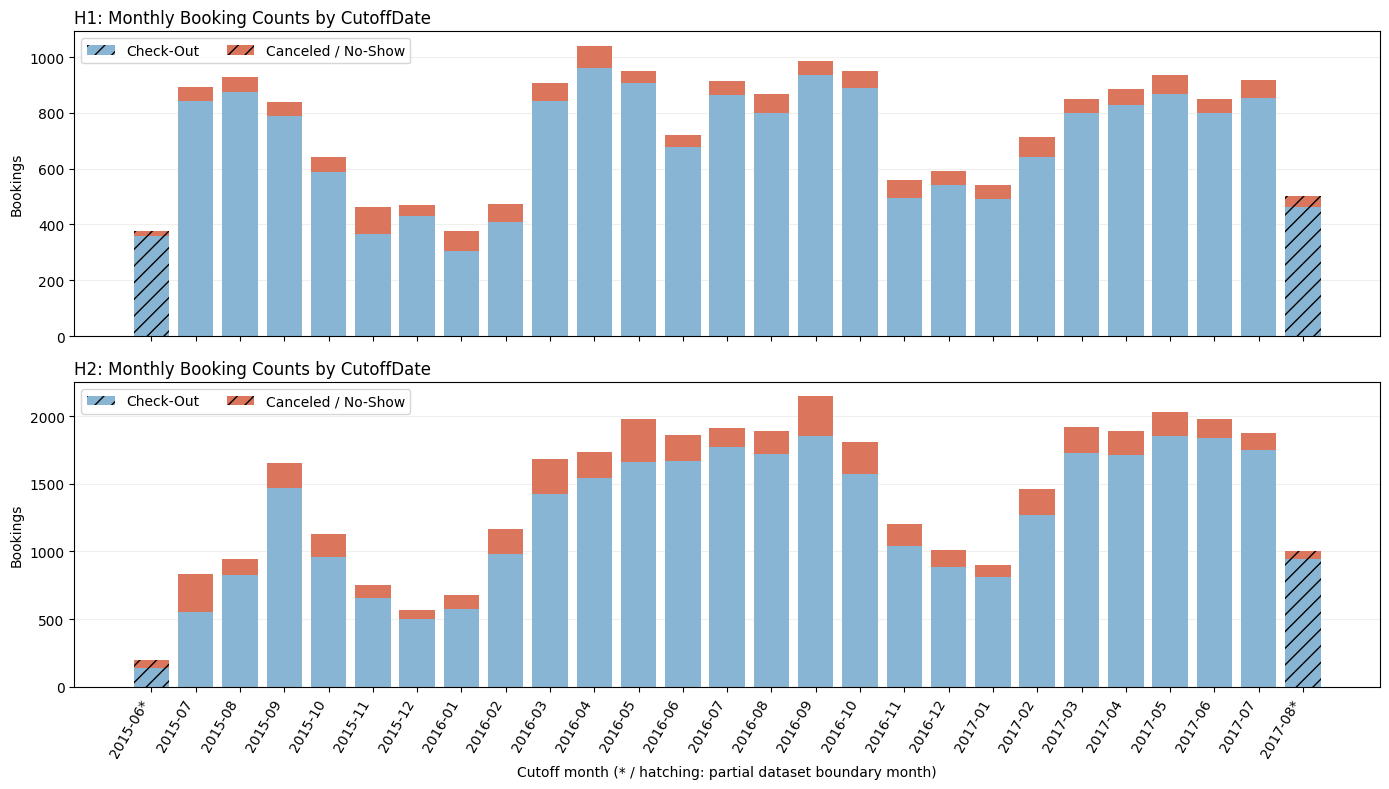

,Hotel,Month,Bookings,Canceled / No-Show,Check-Out,Coverage
0,H1,2015-06,377,18,359,Partial boundary month
1,H1,2015-07,891,47,844,Full calendar month
2,H1,2015-08,928,54,874,Full calendar month
3,H1,2015-09,838,51,787,Full calendar month
4,H1,2015-10,643,56,587,Full calendar month
5,H1,2015-11,462,95,367,Full calendar month
6,H1,2015-12,471,40,431,Full calendar month
7,H1,2016-01,375,69,306,Full calendar month
8,H1,2016-02,474,65,409,Full calendar month
9,H1,2016-03,908,64,844,Full calendar month


In [15]:
monthly_booking_frames = []
coverage_rows = []
split_eda_data = {}

for hotel in HOTELS:
    df = tables[hotel]['model'][
        ['Booking_ID', 'CutoffDate', 'ArrivalDate', 'TotalNights', 'IsCanceled']
    ].copy()
    df['CutoffDate'] = pd.to_datetime(df['CutoffDate'], errors='raise')
    if df.empty or df['CutoffDate'].isna().any() or not df['IsCanceled'].isin([0, 1]).all():
        raise ValueError(f'{hotel}: resolve missing dates or invalid labels before split EDA.')
    split_eda_data[hotel] = df

common_first_date = min(df['CutoffDate'].min() for df in split_eda_data.values())
common_last_date = max(df['CutoffDate'].max() for df in split_eda_data.values())
month_axis = pd.period_range(common_first_date, common_last_date, freq='M')

for hotel, df in split_eda_data.items():
    first_date, last_date = df['CutoffDate'].min(), df['CutoffDate'].max()
    coverage_rows.append({
        'Hotel': hotel,
        'First CutoffDate': first_date.date(),
        'Last CutoffDate': last_date.date(),
        'Bookings': len(df),
    })
    monthly = (df.assign(Month=df['CutoffDate'].dt.to_period('M'))
               .groupby('Month')['IsCanceled'].agg(['size', 'sum'])
               .reindex(month_axis, fill_value=0))
    monthly.index.name = 'Month'
    monthly = monthly.rename(columns={'size': 'Bookings', 'sum': 'Canceled / No-Show'})
    monthly['Check-Out'] = monthly['Bookings'] - monthly['Canceled / No-Show']
    monthly['Hotel'] = hotel
    monthly['Coverage'] = [
        'Outside observed range' if month < first_date.to_period('M') or month > last_date.to_period('M')
        else ('Partial boundary month'
              if month.start_time.normalize() < first_date or month.end_time.normalize() > last_date
              else 'Full calendar month')
        for month in month_axis
    ]
    monthly_booking_frames.append(monthly.reset_index())

monthly_booking_counts = pd.concat(monthly_booking_frames, ignore_index=True)
coverage_report = pd.DataFrame(coverage_rows)
display(coverage_report)

fig, axes = plt.subplots(len(HOTELS), 1, figsize=(14, 8), sharex=True)
for ax, hotel in zip(np.atleast_1d(axes), HOTELS):
    monthly = monthly_booking_counts.loc[monthly_booking_counts['Hotel'].eq(hotel)]
    positions = np.arange(len(monthly))
    checkouts = ax.bar(positions, monthly['Check-Out'], color='#88b5d3', label='Check-Out')
    cancellations = ax.bar(
        positions, monthly['Canceled / No-Show'], bottom=monthly['Check-Out'],
        color='#db765d', label='Canceled / No-Show'
    )
    for index, partial in enumerate(monthly['Coverage'].eq('Partial boundary month')):
        if partial:
            checkouts[index].set_hatch('//')
            cancellations[index].set_hatch('//')
    ax.set_title(f'{hotel}: Monthly Booking Counts by CutoffDate', loc='left')
    ax.set_ylabel('Bookings')
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.2)
    ax.legend(loc='upper left', ncol=2)

partial_months = set(monthly_booking_counts.loc[
    monthly_booking_counts['Coverage'].eq('Partial boundary month'), 'Month'
])
axes[-1].set_xticks(np.arange(len(month_axis)))
axes[-1].set_xticklabels(
    [str(month) + ('*' if month in partial_months else '') for month in month_axis],
    rotation=60, ha='right'
)
axes[-1].set_xlabel('Cutoff month (* / hatching: partial dataset boundary month)')
fig.tight_layout()
plt.show()

monthly_display = monthly_booking_counts.copy()
monthly_display['Month'] = monthly_display['Month'].astype(str)
display(monthly_display[
    ['Hotel', 'Month', 'Bookings', 'Canceled / No-Show', 'Check-Out', 'Coverage']
])

**Observation:**

- Both hotels generally have lower booking volumes around November-February and higher volumes around March-October. Several consecutive months in the higher-volume period have broadly similar booking counts.
- H1 usually has fewer cancellations/no-shows than H2. A short test window may therefore provide relatively few positive cases for evaluating H1.


**Decision - candidate test windows:**

Plan for at least 12 months of initial training and approximately four 2-month validation windows. This requires about 20 months of development history, before allowing time for validation labels to become available:
- With approximately 26 months of data, compare final test windows of **2, 3, 4, 5 and 6 months**. Six months is a preliminary upper bound; label availability may require a shorter test.
- Use 2 months as an initial lower bound to avoid evaluating on only one month. Actual booking and cancellation/no-show counts must still be checked.

### III.2 Final Test Window Comparison: 2-6 Months

Test ends on **17 August 2017** inclusive. Subtract 2-6 calendar months from the exclusive end, **18 August**, so candidate test starts/refit dates are on the **18th**. Use [start, end) for all windows.

For each candidate, development has CutoffDate before refit. A development row is available for refit only if LabelAvailableDate is also strictly before refit. The unavailable count refers to development rows, not test rows or CV validation labels. For Check-Out, use the later of ReservationStatusDate and ArrivalDate + TotalNights; otherwise use ReservationStatusDate.

Refit occurs at test start; label readiness requires LabelAvailableDate < refit date.
Development label unavailable at refit = rows excluded from this refit, not rows removed from Gold.
This comparison does not change the selected boundary.

H1: Final Test Window Comparison


,Test months,Refit / test start,Test end (exclusive),Test bookings,Test canceled / no-show,Development bookings,Development ready for refit,Development label unavailable at refit
0,2,2017-06-18,2017-08-18,1790,130,18350,17807,543
1,3,2017-05-18,2017-08-18,2694,194,17446,16876,570
2,4,2017-04-18,2017-08-18,3576,249,16564,16019,545
3,5,2017-03-18,2017-08-18,4533,312,15607,15105,502
4,6,2017-02-18,2017-08-18,5230,356,14910,14473,437



H2: Final Test Window Comparison


,Test months,Refit / test start,Test end (exclusive),Test bookings,Test canceled / no-show,Development bookings,Development ready for refit,Development label unavailable at refit
0,2,2017-06-18,2017-08-18,3759,246,34474,33416,1058
1,3,2017-05-18,2017-08-18,5761,382,32472,31388,1084
2,4,2017-04-18,2017-08-18,7748,610,30485,29468,1017
3,5,2017-03-18,2017-08-18,9661,792,28572,27565,1007
4,6,2017-02-18,2017-08-18,11312,953,26921,26063,858


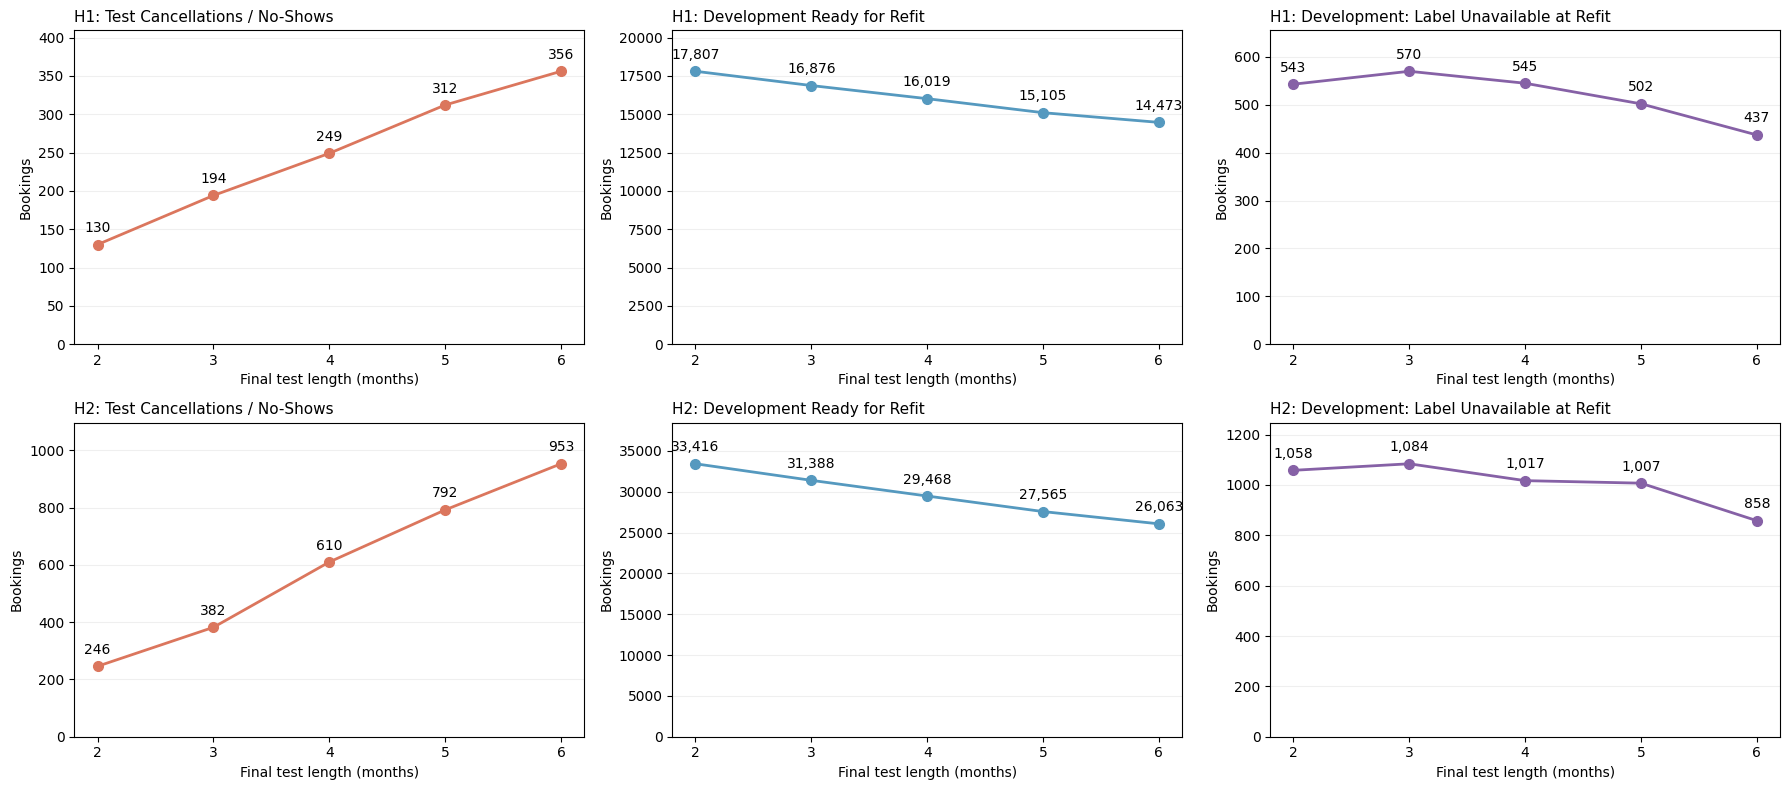

In [2]:
test_end_exclusive = common_last_date.normalize() + pd.Timedelta(days=1)
test_window_rows = []
label_ready_data = {}

for hotel, df in split_eda_data.items():
    labels = tables[hotel]['labels'][
        ['Booking_ID', 'ReservationStatus', 'ReservationStatusDate']
    ]
    joined = df.merge(labels, on='Booking_ID', how='left', validate='one_to_one')
    status_date = pd.to_datetime(joined['ReservationStatusDate'], errors='raise')
    arrival = pd.to_datetime(joined['ArrivalDate'], errors='raise')
    expected_checkout = arrival + pd.to_timedelta(joined['TotalNights'], unit='D')
    checkouts = joined['ReservationStatus'].eq('Check-Out')
    if (status_date.isna().any() or expected_checkout.loc[checkouts].isna().any()
            or not joined['ReservationStatus'].isin(['Check-Out', 'Canceled', 'No-Show']).all()):
        raise ValueError(f'{hotel}: resolve missing or invalid outcomes before checking label readiness.')
    later_checkout_date = pd.concat([status_date, expected_checkout], axis=1).max(axis=1, skipna=False)
    joined['LabelAvailableDate'] = status_date.where(~checkouts, later_checkout_date)
    label_ready_data[hotel] = joined

    for months in range(2, 7):
        test_start = test_end_exclusive - pd.DateOffset(months=months)
        development = joined.loc[joined['CutoffDate'].lt(test_start)]
        test = joined.loc[
            joined['CutoffDate'].ge(test_start) & joined['CutoffDate'].lt(test_end_exclusive)
        ]
        ready = development['LabelAvailableDate'].lt(test_start)
        ready_count = int(ready.sum())
        unavailable_count = int((~ready).sum())
        if len(development) + len(test) != len(joined):
            raise ValueError(f'{hotel}: candidate windows do not cover Gold exactly once.')
        test_window_rows.append({
            'Hotel': hotel,
            'Test months': months,
            'Refit / test start': test_start.date(),
            'Test end (exclusive)': test_end_exclusive.date(),
            'Test bookings': len(test),
            'Test canceled / no-show': int(test['IsCanceled'].sum()),
            'Development bookings': len(development),
            'Development ready for refit': ready_count,
            'Development label unavailable at refit': unavailable_count,
        })

test_window_comparison = pd.DataFrame(test_window_rows)
print('Refit occurs at test start; label readiness requires LabelAvailableDate < refit date.')
print('Development label unavailable at refit = rows excluded from this refit, not rows removed from Gold.')
print('This comparison does not change the selected boundary.')
for hotel in HOTELS:
    print(f'\n{hotel}: Final Test Window Comparison')
    with pd.option_context('display.max_columns', None, 'display.width', 220):
        display(test_window_comparison.loc[test_window_comparison['Hotel'].eq(hotel)]
                .drop(columns='Hotel').reset_index(drop=True))

# Each row is one hotel; columns show evaluation cases, usable training data and excluded development rows.
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True)
panel_metrics = [
    ('Test canceled / no-show', 'Test Cancellations / No-Shows', '#db765d'),
    ('Development ready for refit', 'Development Ready for Refit', '#5599bf'),
    ('Development label unavailable at refit', 'Development: Label Unavailable at Refit', '#8661a6'),
]

for row, hotel in enumerate(HOTELS):
    comparison = (test_window_comparison.loc[test_window_comparison['Hotel'].eq(hotel)]
                  .sort_values('Test months'))
    for column, (metric, title, color) in enumerate(panel_metrics):
        ax = axes[row, column]
        values = comparison[metric]
        ax.plot(comparison['Test months'], values, color=color,
                marker='o', markersize=7, linewidth=2)
        for month, value in zip(comparison['Test months'], values):
            ax.annotate(f'{int(value):,}', (month, value),
                        xytext=(0, 9), textcoords='offset points', ha='center')
        ax.set_title(f'{hotel}: {title}', loc='left', fontsize=11)
        ax.set_xlabel('Final test length (months)')
        ax.set_ylabel('Bookings')
        ax.set_xticks([2, 3, 4, 5, 6])
        ax.tick_params(axis='x', labelbottom=True)
        ax.set_ylim(0, values.max() * 1.15)
        ax.set_axisbelow(True)
        ax.grid(axis='y', alpha=0.2)

fig.tight_layout()
plt.show()

**Observation:**

- Longer tests provide more cancellation/no-show cases for evaluation, but leave fewer label-ready bookings for the model to learn from. There is no clear elbow point in these plots.
- For H1, development rows excluded at refit show a noticeable decline as test length increases from 4 to 6 months. H2 shows a similar downward pattern, but the 4- and 5-month options differ little; the decrease is more noticeable at 6 months.

**Decision - next comparison:** Advance **4-, 5- and 6-month tests** to the CV schedule comparison. They provide more cancellation/no-show cases and broader time coverage than 2-3 months, while development rows excluded at refit decline across the 4-6 month options. These trade-offs justify checking their CV feasibility next; they do not establish a best test length.

### III.3 Temporal CV Schedule Comparison: 4-6 Month Test

**Trial assumption for this comparison:** use **12 months of initial training**, with the first CV fit on **17 June 2016**. This trial does not replace the initial-training decision in III.4. Compare **4-, 5- and 6-month tests**, with final refit on **18 April, 18 March and 18 February 2017**. For each test, compare **A: four 2-month validation windows** (17 June-16 February) and **B: three 3-month windows** (17 June-16 March).

Training requires both CutoffDate and LabelAvailableDate before each fold fit. Check validation label availability before final refit separately. If validation overlaps test, flag the whole fold and do not count its validation outcomes. No test boundary or fold is adjusted automatically.

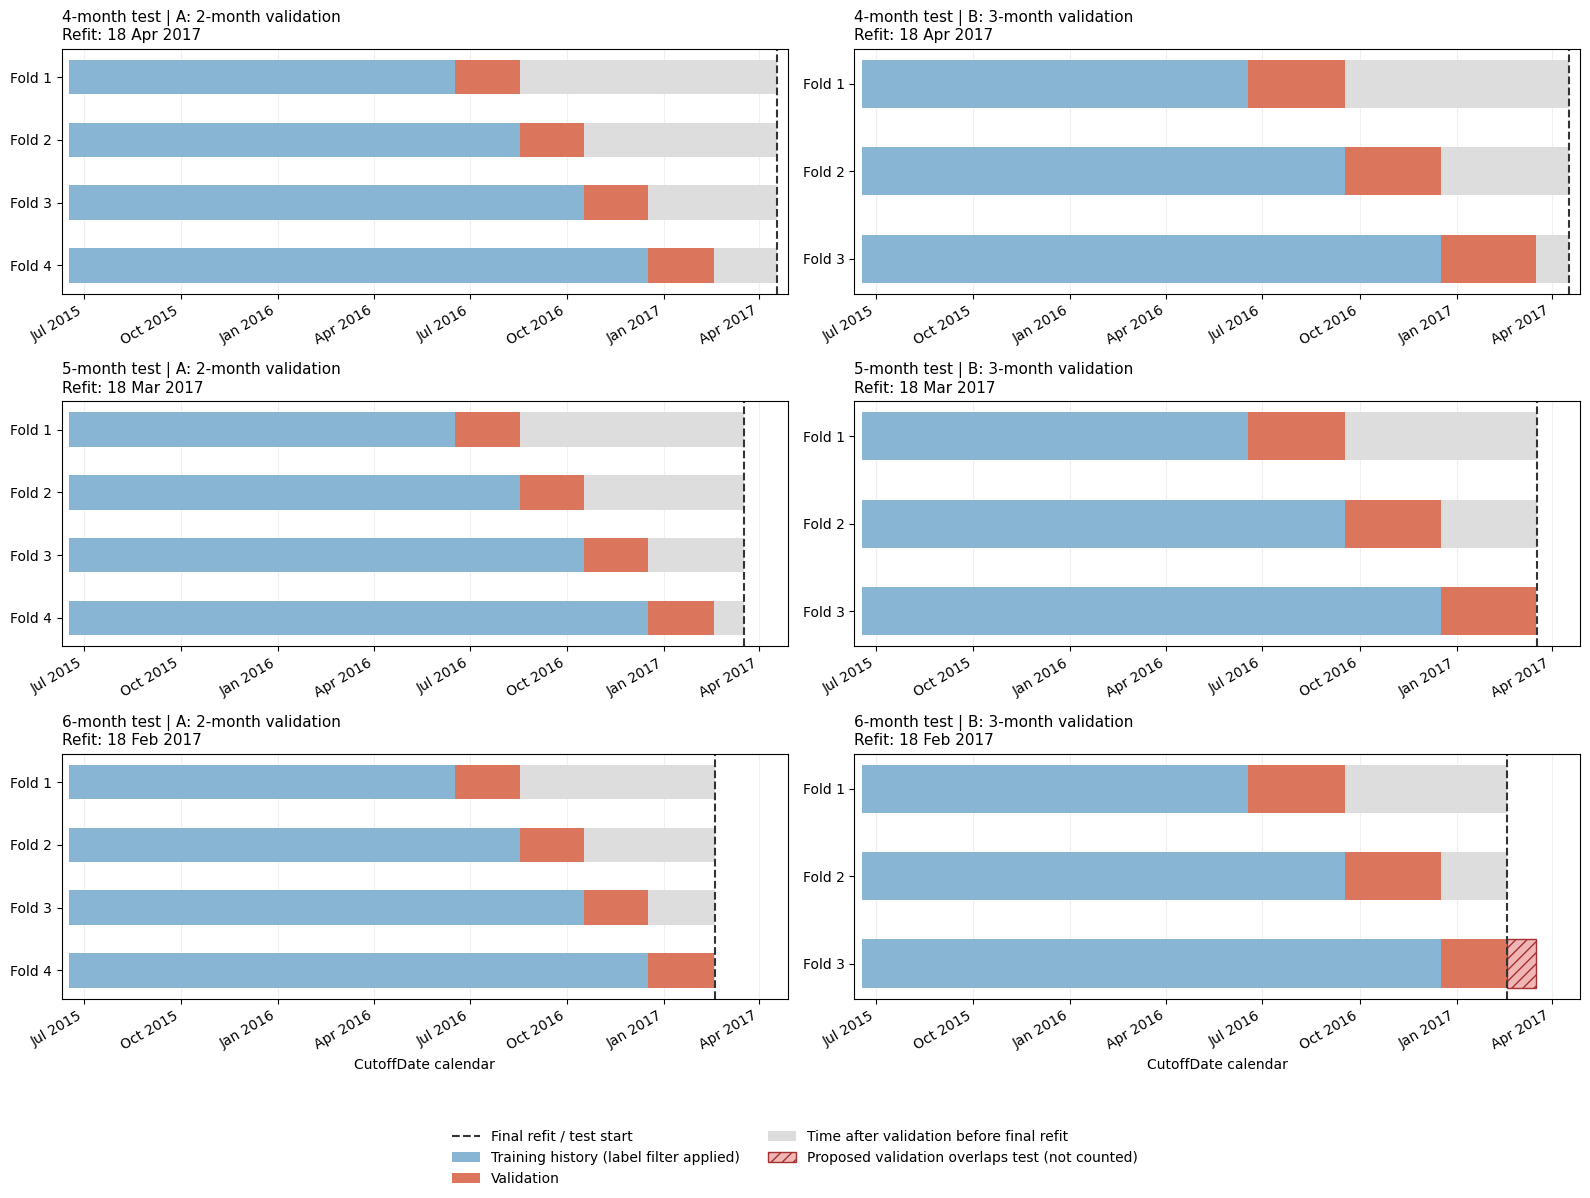

Intervals use [start, end); label readiness requires LabelAvailableDate < fit date.
Not counted = the full proposed validation window overlaps test; no partial fold is used.

OPTION: 4-MONTH TEST | FINAL REFIT: 18 April 2017

H1: Training and Validation Counts


,Plan,Fold,Fit date,"Validation [start, end)",Label-ready train bookings,Train canceled / no-show,Validation bookings,Validation canceled / no-show,Validation labels pending at final refit,All validation labels ready from,Timing status
0,A: 2-month validation,1,2016-06-17,2016-06-17 / 2016-08-17,8253,697,1695,105,0,2016-09-14,Pass
1,A: 2-month validation,2,2016-08-17,2016-08-17 / 2016-10-17,9915,792,1929,125,0,2016-11-15,Pass
2,A: 2-month validation,3,2016-10-17,2016-10-17 / 2016-12-17,11751,912,1372,112,0,2017-01-15,Pass
3,A: 2-month validation,4,2016-12-17,2016-12-17 / 2017-02-17,13354,1030,1141,116,0,2017-04-10,Pass
4,B: 3-month validation,1,2016-06-17,2016-06-17 / 2016-09-17,8253,697,2611,161,0,2016-10-16,Pass
5,B: 3-month validation,2,2016-09-17,2016-09-17 / 2016-12-17,10794,857,2385,181,0,2017-01-15,Pass
6,B: 3-month validation,3,2016-12-17,2016-12-17 / 2017-03-17,13354,1030,1803,157,0,2017-04-13,Pass


A: 2-month validation: 0 validation labels pending at final refit; all labels ready from 2017-04-10.
B: 3-month validation: 0 validation labels pending at final refit; all labels ready from 2017-04-13.

H2: Training and Validation Counts


,Plan,Fold,Fit date,"Validation [start, end)",Label-ready train bookings,Train canceled / no-show,Validation bookings,Validation canceled / no-show,Validation labels pending at final refit,All validation labels ready from,Timing status
0,A: 2-month validation,1,2016-06-17,2016-06-17 / 2016-08-17,13350,2102,3662,316,0,2016-09-13,Pass
1,A: 2-month validation,2,2016-08-17,2016-08-17 / 2016-10-17,17047,2417,4101,513,0,2016-11-07,Pass
2,A: 2-month validation,3,2016-10-17,2016-10-17 / 2016-12-17,21147,2891,2589,330,0,2017-01-09,Pass
3,A: 2-month validation,4,2016-12-17,2016-12-17 / 2017-02-17,24162,3281,2131,252,0,2017-03-10,Pass
4,B: 3-month validation,1,2016-06-17,2016-06-17 / 2016-09-17,13350,2102,5732,500,0,2016-10-10,Pass
5,B: 3-month validation,2,2016-09-17,2016-09-17 / 2016-12-17,18999,2611,4620,659,0,2017-01-09,Pass
6,B: 3-month validation,3,2016-12-17,2016-12-17 / 2017-03-17,24162,3281,3770,419,0,2017-04-09,Pass


A: 2-month validation: 0 validation labels pending at final refit; all labels ready from 2017-03-10.
B: 3-month validation: 0 validation labels pending at final refit; all labels ready from 2017-04-09.

OPTION: 5-MONTH TEST | FINAL REFIT: 18 March 2017

H1: Training and Validation Counts


,Plan,Fold,Fit date,"Validation [start, end)",Label-ready train bookings,Train canceled / no-show,Validation bookings,Validation canceled / no-show,Validation labels pending at final refit,All validation labels ready from,Timing status
0,A: 2-month validation,1,2016-06-17,2016-06-17 / 2016-08-17,8253,697,1695,105,0,2016-09-14,Pass
1,A: 2-month validation,2,2016-08-17,2016-08-17 / 2016-10-17,9915,792,1929,125,0,2016-11-15,Pass
2,A: 2-month validation,3,2016-10-17,2016-10-17 / 2016-12-17,11751,912,1372,112,0,2017-01-15,Pass
3,A: 2-month validation,4,2016-12-17,2016-12-17 / 2017-02-17,13354,1030,1141,116,21,2017-04-10,Pending labels
4,B: 3-month validation,1,2016-06-17,2016-06-17 / 2016-09-17,8253,697,2611,161,0,2016-10-16,Pass
5,B: 3-month validation,2,2016-09-17,2016-09-17 / 2016-12-17,10794,857,2385,181,0,2017-01-15,Pass
6,B: 3-month validation,3,2016-12-17,2016-12-17 / 2017-03-17,13354,1030,1803,157,461,2017-04-13,Pending labels


... (3 outputs left out)

,Plan,Fold,Fit date,"Validation [start, end)",Label-ready train bookings,Train canceled / no-show,Validation bookings,Validation canceled / no-show,Validation labels pending at final refit,All validation labels ready from,Timing status
0,A: 2-month validation,1,2016-06-17,2016-06-17 / 2016-08-17,8253,697,1695,105,0,2016-09-14,Pass
1,A: 2-month validation,2,2016-08-17,2016-08-17 / 2016-10-17,9915,792,1929,125,0,2016-11-15,Pass
2,A: 2-month validation,3,2016-10-17,2016-10-17 / 2016-12-17,11751,912,1372,112,0,2017-01-15,Pass
3,A: 2-month validation,4,2016-12-17,2016-12-17 / 2017-02-17,13354,1030,1141,116,431,2017-04-10,Pending labels
4,B: 3-month validation,1,2016-06-17,2016-06-17 / 2016-09-17,8253,697,2611,161,0,2016-10-16,Pass
5,B: 3-month validation,2,2016-09-17,2016-09-17 / 2016-12-17,10794,857,2385,181,0,2017-01-15,Pass
6,B: 3-month validation,3,2016-12-17,2016-12-17 / 2017-03-17,13354,1030,Not counted,Not counted,Not counted,Not counted,Overlaps test


A: 2-month validation: 431 validation labels pending at final refit; all labels ready from 2017-04-10.
B: 3-month validation: INFEASIBLE AS DRAWN - validation overlaps test. Overlapping-fold outcomes were not counted.

H2: Training and Validation Counts


,Plan,Fold,Fit date,"Validation [start, end)",Label-ready train bookings,Train canceled / no-show,Validation bookings,Validation canceled / no-show,Validation labels pending at final refit,All validation labels ready from,Timing status
0,A: 2-month validation,1,2016-06-17,2016-06-17 / 2016-08-17,13350,2102,3662,316,0,2016-09-13,Pass
1,A: 2-month validation,2,2016-08-17,2016-08-17 / 2016-10-17,17047,2417,4101,513,0,2016-11-07,Pass
2,A: 2-month validation,3,2016-10-17,2016-10-17 / 2016-12-17,21147,2891,2589,330,0,2017-01-09,Pass
3,A: 2-month validation,4,2016-12-17,2016-12-17 / 2017-02-17,24162,3281,2131,252,802,2017-03-10,Pending labels
4,B: 3-month validation,1,2016-06-17,2016-06-17 / 2016-09-17,13350,2102,5732,500,0,2016-10-10,Pass
5,B: 3-month validation,2,2016-09-17,2016-09-17 / 2016-12-17,18999,2611,4620,659,0,2017-01-09,Pass
6,B: 3-month validation,3,2016-12-17,2016-12-17 / 2017-03-17,24162,3281,Not counted,Not counted,Not counted,Not counted,Overlaps test


A: 2-month validation: 802 validation labels pending at final refit; all labels ready from 2017-03-10.
B: 3-month validation: INFEASIBLE AS DRAWN - validation overlaps test. Overlapping-fold outcomes were not counted.
First CV fit: 17 June 2016 (12-month initial training). Test length and the complete CV calendar remain under comparison.


In [2]:
# Trial test/CV calendars; the initial training period is now 12 calendar months.
cv_trial_test_options = (4, 5, 6)
cv_first_fit = common_first_date + pd.DateOffset(months=12)
cv_plans = {'A: 2-month validation': (2, 4), 'B: 3-month validation': (3, 3)}
cv_schedule_rows = []

for test_months in cv_trial_test_options:
    final_refit = test_end_exclusive - pd.DateOffset(months=test_months)
    for plan, (validation_months, folds) in cv_plans.items():
        for fold in range(1, folds + 1):
            fit_date = cv_first_fit + pd.DateOffset(months=(fold - 1) * validation_months)
            validation_end = fit_date + pd.DateOffset(months=validation_months)
            cv_schedule_rows.append({
                'Test months': test_months, 'Final refit': final_refit,
                'Plan': plan, 'Fold': fold, 'Fit date': fit_date,
                'Validation start': fit_date, 'Validation end': validation_end,
                'Overlaps test': validation_end > final_refit,
            })

cv_schedule = pd.DataFrame(cv_schedule_rows)
cv_count_rows = []

for hotel in HOTELS:
    df = label_ready_data[hotel]
    for _, schedule in cv_schedule.iterrows():
        final_refit = schedule['Final refit']
        fit_date = schedule['Fit date']
        development = df.loc[df['CutoffDate'].lt(final_refit)]
        train = development.loc[
            development['CutoffDate'].lt(fit_date)
            & development['LabelAvailableDate'].lt(fit_date)
        ]
        row = {
            'Hotel': hotel, 'Test months': schedule['Test months'],
            'Plan': schedule['Plan'], 'Fold': schedule['Fold'],
            'Fit date': fit_date.date(),
            'Validation [start, end)': (
                f"{schedule['Validation start']:%Y-%m-%d} / {schedule['Validation end']:%Y-%m-%d}"
            ),
            'Label-ready train bookings': len(train),
            'Train canceled / no-show': int(train['IsCanceled'].sum()),
            'Validation bookings': None,
            'Validation canceled / no-show': None,
            'Validation labels pending at final refit': None,
            'All validation labels ready from': None,
            'Timing status': 'Overlaps test',
        }
        # Do not inspect outcomes of a proposed validation fold that crosses into test.
        if not schedule['Overlaps test']:
            validation = development.loc[
                development['CutoffDate'].ge(schedule['Validation start'])
                & development['CutoffDate'].lt(schedule['Validation end'])
            ]
            pending = int(validation['LabelAvailableDate'].ge(final_refit).sum())
            row.update({
                'Validation bookings': len(validation),
                'Validation canceled / no-show': int(validation['IsCanceled'].sum()),
                'Validation labels pending at final refit': pending,
                'All validation labels ready from': (
                    validation['LabelAvailableDate'].max().normalize() + pd.Timedelta(days=1)
                ).date() if not validation.empty else None,
                'Timing status': 'Pending labels' if pending else 'Pass',
            })
        cv_count_rows.append(row)

cv_fold_counts = pd.DataFrame(cv_count_rows)
for column in ['Validation bookings', 'Validation canceled / no-show',
               'Validation labels pending at final refit']:
    cv_fold_counts[column] = cv_fold_counts[column].astype('Int64')

# Rows compare test length; columns compare the unchanged CV calendars.
# Training bars show date spans, with the per-booking label filter applied in the counts.
fig, axes = plt.subplots(len(cv_trial_test_options), 2, figsize=(16, 12), sharex=True)
plot_end = max(cv_schedule['Validation end'].max(), cv_schedule['Final refit'].max())
tick_dates = pd.date_range('2015-07-01', plot_end, freq='3MS')

for row, test_months in enumerate(cv_trial_test_options):
    for column, plan in enumerate(cv_plans):
        ax = axes[row, column]
        schedule = cv_schedule.loc[
            cv_schedule['Test months'].eq(test_months) & cv_schedule['Plan'].eq(plan)
        ]
        final_refit = schedule['Final refit'].iloc[0]
        for position, (_, fold) in enumerate(schedule.iterrows()):
            ax.barh(position, (fold['Fit date'] - common_first_date).days,
                    left=common_first_date, height=0.55, color='#88b5d3',
                    label='Training history (label filter applied)' if position == 0 else None)
            validation_limit = min(fold['Validation end'], final_refit)
            ax.barh(position, (validation_limit - fold['Validation start']).days,
                    left=fold['Validation start'], height=0.55, color='#db765d',
                    label='Validation' if position == 0 else None)
            if fold['Overlaps test']:
                ax.barh(position, (fold['Validation end'] - final_refit).days,
                        left=final_refit, height=0.55, color='#f0b6b6',
                        edgecolor='#a43030', hatch='///',
                        label='Proposed validation overlaps test (not counted)')
            else:
                ax.barh(position, (final_refit - fold['Validation end']).days,
                        left=fold['Validation end'], height=0.55, color='#dddddd',
                        label='Time after validation before final refit' if position == 0 else None)
        ax.axvline(final_refit, color='#333333', linestyle='--', linewidth=1.5,
                   label='Final refit / test start')
        ax.set_title(f'{test_months}-month test | {plan}\nRefit: {final_refit:%d %b %Y}',
                     loc='left', fontsize=11)
        ax.set_yticks(range(len(schedule)))
        ax.set_yticklabels([f"Fold {fold}" for fold in schedule['Fold']])
        ax.invert_yaxis()
        ax.set_xticks(tick_dates)
        ax.set_xticklabels([date.strftime('%b %Y') for date in tick_dates], rotation=30, ha='right')
        ax.set_xlim(common_first_date - pd.Timedelta(days=7), plot_end + pd.Timedelta(days=10))
        ax.tick_params(axis='x', labelbottom=True)
        ax.set_axisbelow(True)
        ax.grid(axis='x', alpha=0.2)
        if row == len(cv_trial_test_options) - 1:
            ax.set_xlabel('CutoffDate calendar')

legend_items = {}
for ax in axes.flat:
    handles, labels = ax.get_legend_handles_labels()
    legend_items.update(zip(labels, handles))
fig.legend(legend_items.values(), legend_items.keys(), loc='lower center',
           ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

print('Intervals use [start, end); label readiness requires LabelAvailableDate < fit date.')
print('Not counted = the full proposed validation window overlaps test; no partial fold is used.')
for test_months in cv_trial_test_options:
    final_refit = test_end_exclusive - pd.DateOffset(months=test_months)
    print(f'\nOPTION: {test_months}-MONTH TEST | FINAL REFIT: {final_refit:%d %B %Y}')
    for hotel in HOTELS:
        print(f'\n{hotel}: Training and Validation Counts')
        counts = cv_fold_counts.loc[
            cv_fold_counts['Test months'].eq(test_months) & cv_fold_counts['Hotel'].eq(hotel)
        ].drop(columns=['Hotel', 'Test months'])
        with pd.option_context('display.max_columns', None, 'display.width', 220):
            display(counts.astype(object).where(counts.notna(), 'Not counted').reset_index(drop=True))
        for plan in cv_plans:
            plan_counts = counts.loc[counts['Plan'].eq(plan)]
            if plan_counts['Timing status'].eq('Overlaps test').any():
                print(f'{plan}: INFEASIBLE AS DRAWN - validation overlaps test. '
                      'Overlapping-fold outcomes were not counted.')
            else:
                pending = int(plan_counts['Validation labels pending at final refit'].sum())
                ready_from = plan_counts['All validation labels ready from'].max()
                print(f'{plan}: {pending} validation labels pending at final refit; '
                      f'all labels ready from {ready_from}.')

print(f'First CV fit: {cv_first_fit:%d %B %Y} (12-month initial training). Test length and the complete CV calendar remain under comparison.')

**Observation:**

Only the 4-month test passes all validation-label timing checks for both hotels

- **4-month test:** both A and B have all validation labels available before refit.
- **5-month test:** A has 21 H1 labels pending and none for H2. B has 461 H1 and 939 H2 labels pending, although its validation no longer overlaps test.
- **6-month test:** A no longer overlaps test but still has 431 H1 and 802 H2 validation labels pending. B's final validation overlaps test.

**Decision:**

- Select a **4-month final test**, both hotels have all validation labels available before final refit on **18 April 2017**.
- Use **2-month validation windows** with expanding-window CV, because it provides four validation folds, with all validation labels available before final refit on **18 April 2017**.

### III.4 Initial Training Comparison: 12–13 Months

Compare 12, approximately 12.5 and 13 months of initial training, keeping four 2-month validation windows and final refit on 18 April 2017. With 14 months of initial training, the 4th validation window still fits before test, but its labels are not all available by refit. Only three folds pass the label-timing check. The 12–13 month options retain all four.

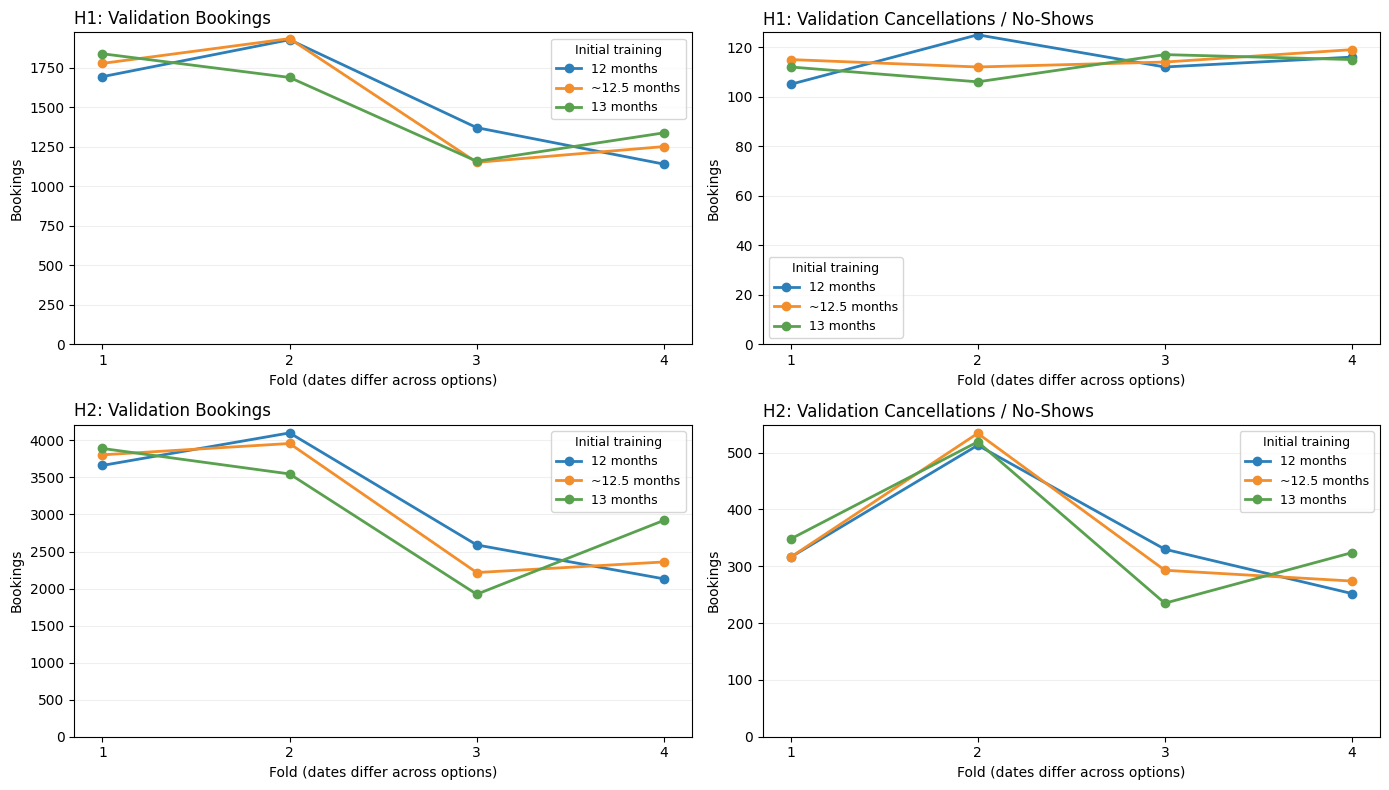

Final refit: 18 April 2017. Intervals use [start, end); available labels must have an earlier date than refit.

H1: Validation Counts and Label Readiness


,Initial training,Fold,"Validation [start, end)",Validation bookings,Canceled / No-Show,Labels ready before final refit,Labels pending at final refit
0,12 months,1,2016-06-17 / 2016-08-17,1695,105,1695,0
1,12 months,2,2016-08-17 / 2016-10-17,1929,125,1929,0
2,12 months,3,2016-10-17 / 2016-12-17,1372,112,1372,0
3,12 months,4,2016-12-17 / 2017-02-17,1141,116,1141,0
4,~12.5 months,1,2016-07-01 / 2016-09-01,1779,115,1779,0
5,~12.5 months,2,2016-09-01 / 2016-11-01,1936,112,1936,0
6,~12.5 months,3,2016-11-01 / 2017-01-01,1152,114,1152,0
7,~12.5 months,4,2017-01-01 / 2017-03-01,1252,119,1252,0
8,13 months,1,2016-07-17 / 2016-09-17,1840,112,1840,0
9,13 months,2,2016-09-17 / 2016-11-17,1690,106,1690,0


12 months: 105-125 cancellations/no-shows per fold; 0 validation labels pending at final refit.
~12.5 months: 112-119 cancellations/no-shows per fold; 0 validation labels pending at final refit.
13 months: 106-117 cancellations/no-shows per fold; 0 validation labels pending at final refit.

H2: Validation Counts and Label Readiness


,Initial training,Fold,"Validation [start, end)",Validation bookings,Canceled / No-Show,Labels ready before final refit,Labels pending at final refit
0,12 months,1,2016-06-17 / 2016-08-17,3662,316,3662,0
1,12 months,2,2016-08-17 / 2016-10-17,4101,513,4101,0
2,12 months,3,2016-10-17 / 2016-12-17,2589,330,2589,0
3,12 months,4,2016-12-17 / 2017-02-17,2131,252,2131,0
4,~12.5 months,1,2016-07-01 / 2016-09-01,3805,316,3805,0
5,~12.5 months,2,2016-09-01 / 2016-11-01,3958,534,3958,0
6,~12.5 months,3,2016-11-01 / 2017-01-01,2216,293,2216,0
7,~12.5 months,4,2017-01-01 / 2017-03-01,2359,274,2359,0
8,13 months,1,2016-07-17 / 2016-09-17,3891,348,3891,0
9,13 months,2,2016-09-17 / 2016-11-17,3547,519,3547,0


12 months: 252-513 cancellations/no-shows per fold; 0 validation labels pending at final refit.
~12.5 months: 274-534 cancellations/no-shows per fold; 0 validation labels pending at final refit.
13 months: 235-519 cancellations/no-shows per fold; 0 validation labels pending at final refit.
Counts alone do not establish metric precision or the best initial training length.


In [18]:
initial_comparison_refit = test_end_exclusive - pd.DateOffset(months=4)
initial_train_options = {
    '12 months': common_first_date + pd.DateOffset(months=12),
    '~12.5 months': pd.Timestamp('2016-07-01'),
    '13 months': common_first_date + pd.DateOffset(months=13),
}
initial_comparison_folds = 4
initial_comparison_validation_months = 2
initial_validation_rows = []

for option, first_fit in initial_train_options.items():
    for fold in range(1, initial_comparison_folds + 1):
        validation_start = first_fit + pd.DateOffset(
            months=(fold - 1) * initial_comparison_validation_months
        )
        validation_end = first_fit + pd.DateOffset(
            months=fold * initial_comparison_validation_months
        )
        if validation_end > initial_comparison_refit:
            raise ValueError(f'{option}, fold {fold}: validation overlaps the final test.')
        for hotel in HOTELS:
            df = label_ready_data[hotel]
            validation = df.loc[
                df['CutoffDate'].ge(validation_start) & df['CutoffDate'].lt(validation_end)
            ]
            label_ready = validation['LabelAvailableDate'].lt(initial_comparison_refit)
            initial_validation_rows.append({
                'Hotel': hotel, 'Initial training': option, 'Fold': fold,
                'Validation [start, end)': f'{validation_start:%Y-%m-%d} / {validation_end:%Y-%m-%d}',
                'Validation bookings': len(validation),
                'Canceled / No-Show': int(validation['IsCanceled'].sum()),
                'Labels ready before final refit': int(label_ready.sum()),
                'Labels pending at final refit': int((~label_ready).sum()),
            })

initial_validation_counts = pd.DataFrame(initial_validation_rows)

# Compare counts, not model scores: the same fold number covers different dates.
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
initial_option_colors = {
    '12 months': '#2c7fb8', '~12.5 months': '#f28e2b', '13 months': '#59a14f'
}
initial_panel_metrics = [
    ('Validation bookings', 'Validation Bookings'),
    ('Canceled / No-Show', 'Validation Cancellations / No-Shows'),
]
for row, hotel in enumerate(HOTELS):
    for column, (metric, title) in enumerate(initial_panel_metrics):
        ax = axes[row, column]
        for option, color in initial_option_colors.items():
            counts = initial_validation_counts.loc[
                initial_validation_counts['Hotel'].eq(hotel)
                & initial_validation_counts['Initial training'].eq(option)
            ].sort_values('Fold')
            ax.plot(counts['Fold'], counts[metric], label=option,
                    color=color, marker='o', markersize=6, linewidth=2)
        ax.set_title(f'{hotel}: {title}', loc='left')
        ax.set_xticks(range(1, initial_comparison_folds + 1))
        ax.tick_params(axis='x', labelbottom=True)
        ax.set_xlabel('Fold (dates differ across options)')
        ax.set_ylabel('Bookings')
        ax.set_ylim(bottom=0)
        ax.set_axisbelow(True)
        ax.grid(axis='y', alpha=0.2)
        ax.legend(title='Initial training', fontsize=9, title_fontsize=9)
fig.tight_layout()
plt.show()

print(f'Final refit: {initial_comparison_refit:%d %B %Y}. '
      'Intervals use [start, end); available labels must have an earlier date than refit.')
for hotel in HOTELS:
    print(f'\n{hotel}: Validation Counts and Label Readiness')
    counts = initial_validation_counts.loc[
        initial_validation_counts['Hotel'].eq(hotel)
    ].drop(columns='Hotel')
    with pd.option_context('display.max_columns', None, 'display.width', 200):
        display(counts.reset_index(drop=True))
    for option in initial_train_options:
        option_counts = counts.loc[counts['Initial training'].eq(option)]
        pending = int(option_counts['Labels pending at final refit'].sum())
        positives = option_counts['Canceled / No-Show']
        print(f'{option}: {positives.min()}-{positives.max()} cancellations/no-shows per fold; '
              f'{pending} validation labels pending at final refit.')

print('Counts alone do not establish metric precision or the best initial training length.')

**Observation:**

- All three options retain four validation folds, with all validation labels available before refit on 18 April 2017.
- Validation booking and cancellation/no-show counts are comparable across the options. There is no clear count-based winner.

**Decision:**

Select **~12.5 months of initial training**, with the first CV fit on **1 July 2016**. Since all three options pass the timing checks and have comparable validation counts, prefer the full calendar-month windows: Jul-Aug, Sep-Oct, Nov-Dec and Jan-Feb. These simplify checking and monthly reporting.

### III.5 Split Specification Summary

Use a chronological split based on `CutoffDate`. H1 and H2 use separate models with the same calendar. All intervals use **[start, end)**.

| Setting | Selected specification |
|---|---|
| Development | `CutoffDate < 2017-04-18` |
| Final test | `2017-04-18 <= CutoffDate < 2017-08-18` (4 months) |
| Initial training history | `[2015-06-17, 2016-07-01)` (approximately 12.5 months) |
| Temporal CV | Expanding window; 4 folds with 2-month validation windows |
| Final refit | `2017-04-18` |

**CV calendar**

| Fold | Fit date / validation start | Validation end (exclusive) |
|---|---|---|
| 1 | 2016-07-01 | 2016-09-01 |
| 2 | 2016-09-01 | 2016-11-01 |
| 3 | 2016-11-01 | 2017-01-01 |
| 4 | 2017-01-01 | 2017-03-01 |

**Training and label availability**

- `FitDate = ValidationStart`; the simulation assumes the model is ready when validation starts, without an additional operational delay. Use the fitted model throughout that validation window.
- For Check-Out, `LabelAvailableDate = max(ReservationStatusDate, ArrivalDate + TotalNights)`; for Canceled/No-Show, use `ReservationStatusDate`. This proxy does not change `IsCanceled`.
- At each fit, use development rows with both `CutoffDate < FitDate` and `LabelAvailableDate < FitDate`.
- Retain rows excluded for unavailable labels and recheck them at every later fold and final refit. Partition and validation-window assignments remain based on `CutoffDate`.
- Keep complete validation cohorts. All selected validation labels are available before final refit.

**Final refit and calibration**

- Refit on all development rows eligible on **18 April 2017**. The period **1 March-17 April 2017** remains development; eligible rows from it participate in refit, outside the CV validation/calibration cohort.
- Keep development rows still lacking available labels for potential future retraining.
- For each hotel, fit the calibrator using the selected model configuration's saved temporal out-of-fold probabilities and labels from the four validation folds. Each booking appears once in this cohort.
- Apply the final refitted model, then the calibrator, to test bookings. Test remains reserved for final evaluation; test membership is not filtered by label availability at refit.


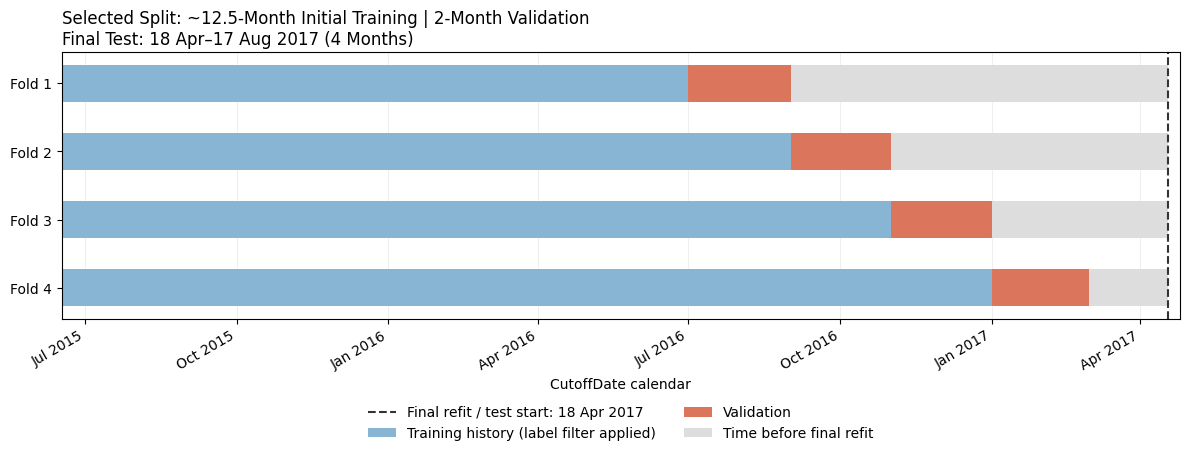

In [23]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt

history_start = pd.Timestamp('2015-06-17')
first_fit = pd.Timestamp('2016-07-01')
final_refit = pd.Timestamp('2017-04-18')

fig, ax = plt.subplots(figsize=(12, 5))

for fold in range(4):
    fit_date = first_fit + pd.DateOffset(months=fold * 2)
    validation_end = fit_date + pd.DateOffset(months=2)

    ax.barh(
        fold, (fit_date - history_start).days,
        left=history_start, height=0.55, color='#88b5d3',
        label='Training history (label filter applied)' if fold == 0 else None,
    )
    ax.barh(
        fold, (validation_end - fit_date).days,
        left=fit_date, height=0.55, color='#db765d',
        label='Validation' if fold == 0 else None,
    )
    ax.barh(
        fold, (final_refit - validation_end).days,
        left=validation_end, height=0.55, color='#dddddd',
        label='Time before final refit' if fold == 0 else None,
    )

ax.axvline(
    final_refit, color='#333333', linestyle='--',
    label='Final refit / test start: 18 Apr 2017',
)

ticks = pd.date_range('2015-07-01', '2017-04-01', freq='3MS')
ax.set_xticks(ticks)
ax.set_xticklabels(
    [date.strftime('%b %Y') for date in ticks],
    rotation=30, ha='right',
)
ax.set_yticks(range(4))
ax.set_yticklabels([f'Fold {i + 1}' for i in range(4)])
ax.invert_yaxis()
ax.set_xlim(history_start, final_refit + pd.Timedelta(days=7))
ax.set_xlabel('CutoffDate calendar')
ax.set_title(
    'Selected Split: ~12.5-Month Initial Training | 2-Month Validation\n'
    'Final Test: 18 Apr–17 Aug 2017 (4 Months)',
    loc='left',
)
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.2)
ax.legend(
    loc='upper center', bbox_to_anchor=(0.5, -0.28),
    ncol=2, frameon=False,
)

fig.tight_layout()
plt.show()

#### III.5.1 Final Split Audit

Audit the selected calendar: approximately 12.5 months of initial training, four 2-month validation folds and a 4-month final test. Run after loading Gold tables; the comparison cells in III.1-III.4 are not required. Label availability uses the agreed proxy and strict date-before-fit rule.

In [2]:
# Final audit of the agreed calendar; requires only the loaded Gold `tables`.
split_audit_first_fit = pd.Timestamp('2016-07-01')
split_audit_refit_date = pd.Timestamp('2017-04-18')
split_audit_test_end = pd.Timestamp('2017-08-18')
split_audit_data = {}
split_audit_train_rows = []
split_audit_validation_rows = []
split_audit_refit_rows = []
split_audit_test_rows = []
split_audit_check_rows = []

for hotel in ('H1', 'H2'):
    model = tables[hotel]['model'][
        ['Booking_ID', 'CutoffDate', 'ArrivalDate', 'TotalNights', 'IsCanceled']
    ].copy()
    labels = tables[hotel]['labels'][
        ['Booking_ID', 'ReservationStatus', 'ReservationStatusDate']
    ].copy()
    df = model.merge(labels, on='Booking_ID', how='left', validate='one_to_one')
    for column in ('CutoffDate', 'ArrivalDate', 'ReservationStatusDate'):
        df[column] = pd.to_datetime(df[column], errors='raise')

    required = ['Booking_ID', 'CutoffDate', 'ArrivalDate', 'TotalNights',
                'IsCanceled', 'ReservationStatus', 'ReservationStatusDate']
    if df[required].isna().any().any() or df.empty:
        raise ValueError(f'{hotel}: resolve missing audit inputs before splitting.')
    expected_label = df['ReservationStatus'].map(
        {'Check-Out': 0, 'Canceled': 1, 'No-Show': 1}
    )
    if expected_label.isna().any() or not df['IsCanceled'].eq(expected_label).all():
        raise ValueError(f'{hotel}: resolve invalid statuses or label/status mismatches.')

    expected_checkout = df['ArrivalDate'] + pd.to_timedelta(df['TotalNights'], unit='D')
    later_date = pd.concat(
        [df['ReservationStatusDate'], expected_checkout], axis=1
    ).max(axis=1, skipna=False)
    df['LabelAvailableDate'] = df['ReservationStatusDate'].where(
        ~df['ReservationStatus'].eq('Check-Out'), later_date
    )
    split_audit_data[hotel] = df
    development = df.loc[df['CutoffDate'].lt(split_audit_refit_date)]
    test = df.loc[
        df['CutoffDate'].ge(split_audit_refit_date)
        & df['CutoffDate'].lt(split_audit_test_end)
    ]
    validation_ids = []

    def record_check(name, passed):
        split_audit_check_rows.append({
            'Hotel': hotel, 'Check': name, 'Result': 'PASS' if passed else 'FAIL'
        })

    record_check('Development + test cover Gold exactly once',
                 len(development) + len(test) == len(df)
                 and not set(development['Booking_ID']) & set(test['Booking_ID']))

    for fold in range(1, 5):
        fit_date = split_audit_first_fit + pd.DateOffset(months=(fold - 1) * 2)
        validation_end = fit_date + pd.DateOffset(months=2)
        candidates = development.loc[development['CutoffDate'].lt(fit_date)]
        ready = candidates['LabelAvailableDate'].lt(fit_date)
        train = candidates.loc[ready]
        unavailable = candidates.loc[~ready]
        validation = development.loc[
            development['CutoffDate'].ge(fit_date)
            & development['CutoffDate'].lt(validation_end)
        ]
        pending = validation['LabelAvailableDate'].ge(split_audit_refit_date)
        validation_ids.extend(validation['Booking_ID'].tolist())

        split_audit_train_rows.append({
            'Hotel': hotel, 'Fold': fold, 'Fit date': fit_date.date(),
            'Rows before label filter': len(candidates),
            'Eligible train rows': len(train),
            'Eligible train positives': int(train['IsCanceled'].sum()),
            'Label unavailable rows': len(unavailable),
        })
        split_audit_validation_rows.append({
            'Hotel': hotel, 'Fold': fold,
            'Start (inclusive)': fit_date.date(),
            'End (exclusive)': validation_end.date(),
            'Validation rows': len(validation),
            'Validation positives': int(validation['IsCanceled'].sum()),
            'Labels ready at final refit': int((~pending).sum()),
            'Labels pending at final refit': int(pending.sum()),
            'All labels ready from (proxy)': (
                validation['LabelAvailableDate'].max() + pd.Timedelta(days=1)
            ).date() if not validation.empty else None,
        })
        record_check(f'Fold {fold}: nonempty train and validation',
                     not train.empty and not validation.empty)
        record_check(f'Fold {fold}: train eligibility and row reconciliation',
                     train['CutoffDate'].lt(fit_date).all()
                     and train['LabelAvailableDate'].lt(fit_date).all()
                     and len(train) + len(unavailable) == len(candidates))
        record_check(f'Fold {fold}: train/validation disjoint; validation before test',
                     not set(train['Booking_ID']) & set(validation['Booking_ID'])
                     and validation_end <= split_audit_refit_date)
        record_check(f'Fold {fold}: validation labels ready before final refit',
                     not pending.any())

    record_check('Calibration membership unique across four validation folds',
                 len(validation_ids) == len(set(validation_ids)))
    refit_ready = development['LabelAvailableDate'].lt(split_audit_refit_date)
    refit = development.loc[refit_ready]
    excluded = development.loc[~refit_ready]
    split_audit_refit_rows.append({
        'Hotel': hotel, 'Fit date': split_audit_refit_date.date(),
        'Development rows': len(development),
        'Development positives': int(development['IsCanceled'].sum()),
        'Eligible refit rows': len(refit),
        'Eligible refit positives': int(refit['IsCanceled'].sum()),
        'Label unavailable rows': len(excluded),
        'Label unavailable positives': int(excluded['IsCanceled'].sum()),
    })
    record_check('Final refit eligibility and row reconciliation',
                 refit['CutoffDate'].lt(split_audit_refit_date).all()
                 and refit['LabelAvailableDate'].lt(split_audit_refit_date).all()
                 and len(refit) + len(excluded) == len(development))

    split_audit_test_rows.append({
        'Hotel': hotel, 'Start (inclusive)': split_audit_refit_date.date(),
        'End (exclusive)': split_audit_test_end.date(),
        'Test rows': len(test), 'Test positives': int(test['IsCanceled'].sum()),
        'Rows with recorded outcomes': int(test['IsCanceled'].notna().sum()),
        'Latest label availability (proxy)': test['LabelAvailableDate'].max().date()
            if not test.empty else None,
        'All labels ready from (proxy)': (
            test['LabelAvailableDate'].max() + pd.Timedelta(days=1)
        ).date() if not test.empty else None,
    })
    record_check('Nonempty test with valid recorded outcomes', not test.empty)

split_audit_train = pd.DataFrame(split_audit_train_rows)
split_audit_validation = pd.DataFrame(split_audit_validation_rows)
split_audit_refit = pd.DataFrame(split_audit_refit_rows)
split_audit_test = pd.DataFrame(split_audit_test_rows)
split_audit_checks = pd.DataFrame(split_audit_check_rows)

print('Positive = canceled / no-show. All intervals use [start, end).')
print('Training requires CutoffDate < FitDate and LabelAvailableDate < FitDate.')
for title, report in [
    ('1. Training eligibility by fold', split_audit_train),
    ('2. Validation counts and label maturity', split_audit_validation),
    ('3. Final refit eligibility', split_audit_refit),
    ('4. Final test counts and recorded outcomes', split_audit_test),
    ('5. Split checks', split_audit_checks),
]:
    print(f'\n{title}')
    with pd.option_context('display.max_columns', None, 'display.width', 240):
        display(report)

print('\nTest membership is not filtered by label availability at final refit.')
print('Test readiness dates are proxy-derived; no operational evaluation date is assumed.')
failed = split_audit_checks.loc[split_audit_checks['Result'].eq('FAIL')]
if not failed.empty:
    raise ValueError('Split audit failed. Review the failed checks above.')
print('All split checks passed. No split files or model artifacts were written.')


Positive = canceled / no-show. All intervals use [start, end).
Training requires CutoffDate < FitDate and LabelAvailableDate < FitDate.

1. Training eligibility by fold


,Hotel,Fold,Fit date,Rows before label filter,Eligible train rows,Eligible train positives,Label unavailable rows
0,H1,1,2016-07-01,9077,8618,719,459
1,H1,2,2016-09-01,10856,10353,825,503
2,H1,3,2016-11-01,12792,12291,945,501
3,H1,4,2017-01-01,13944,13631,1055,313
4,H2,1,2016-07-01,15188,14230,2185,958
5,H2,2,2016-09-01,18993,17962,2517,1031
6,H2,3,2016-11-01,22951,22069,3032,882
7,H2,4,2017-01-01,25167,24605,3350,562



2. Validation counts and label maturity


,Hotel,Fold,Start (inclusive),End (exclusive),Validation rows,Validation positives,Labels ready at final refit,Labels pending at final refit,All labels ready from (proxy)
0,H1,1,2016-07-01,2016-09-01,1779,115,1779,0,2016-09-27
1,H1,2,2016-09-01,2016-11-01,1936,112,1936,0,2016-12-09
2,H1,3,2016-11-01,2017-01-01,1152,114,1152,0,2017-03-08
3,H1,4,2017-01-01,2017-03-01,1252,119,1252,0,2017-04-13
4,H2,1,2016-07-01,2016-09-01,3805,316,3805,0,2016-09-29
5,H2,2,2016-09-01,2016-11-01,3958,534,3958,0,2016-11-22
6,H2,3,2016-11-01,2017-01-01,2216,293,2216,0,2017-01-30
7,H2,4,2017-01-01,2017-03-01,2359,274,2359,0,2017-03-22



3. Final refit eligibility


,Hotel,Fit date,Development rows,Development positives,Eligible refit rows,Eligible refit positives,Label unavailable rows,Label unavailable positives
0,H1,2017-04-18,16564,1269,16019,1250,545,19
1,H2,2017-04-18,30485,3926,29468,3882,1017,44



4. Final test counts and recorded outcomes


,Hotel,Start (inclusive),End (exclusive),Test rows,Test positives,Rows with recorded outcomes,Latest label availability (proxy),All labels ready from (proxy)
0,H1,2017-04-18,2017-08-18,3576,249,3576,2017-09-14,2017-09-15
1,H2,2017-04-18,2017-08-18,7748,610,7748,2017-09-07,2017-09-08



5. Split checks


,Hotel,Check,Result
0,H1,Development + test cover Gold exactly once,PASS
1,H1,Fold 1: nonempty train and validation,PASS
2,H1,Fold 1: train eligibility and row reconciliation,PASS
3,H1,Fold 1: train/validation disjoint; validation ...,PASS
4,H1,Fold 1: validation labels ready before final r...,PASS
5,H1,Fold 2: nonempty train and validation,PASS
6,H1,Fold 2: train eligibility and row reconciliation,PASS
7,H1,Fold 2: train/validation disjoint; validation ...,PASS
8,H1,Fold 2: validation labels ready before final r...,PASS
9,H1,Fold 3: nonempty train and validation,PASS



Test membership is not filtered by label availability at final refit.
Test readiness dates are proxy-derived; no operational evaluation date is assumed.
All split checks passed. No split files or model artifacts were written.
